# Как матрица преобразует данные?
## Занятие 10 — матрицы и матричное умножение

В первых занятиях каждое наблюдение было вектором, а датасет — облаком точек.
Теперь научимся записывать несколько векторов одной матрицей и выполнять операции сразу с ними всеми.

Разберём, **как вычисляется матричное произведение и что оно делает с векторами**.
В начале вернёмся к росту и весу из Davis; для вычислений и геометрии возьмём небольшие учебные примеры.
В конце — четыре задачи для практики: поворот, оценка стоимости автомобилей и небольшая нейросеть с заданными весами.

Запускайте ячейки по порядку. Сначала предскажите результат, затем проверьте его в интерактиве и в NumPy.
Определения и графики находятся в свёрнутых HTML-ячейках, примеры Python открыты.
Ноутбук содержит весь код и небольшую таблицу данных. Формулы загружаются через MathJax;
после запуска интерактивы работают без обращений к Python.

In [ ]:
#@title Оформление и хелперы визуализации — запустите первой { display-mode: "form" }
from IPython.display import HTML, display

CSS = r"""
.vec-root{--bg:#12161c;--surface:#1a1f27;--ink:#e6e9ec;--soft:#a7b0ba;--line:#2a313b;
  --green:#5fd08a;--blue:#6ab0f3;--amber:#e0b25a;--rose:#e0757f;
  font-family:Georgia,'Times New Roman',serif;color:var(--ink);
  background:var(--bg);border-radius:14px;padding:2px 0;}
.vec-root .wrap{max-width:820px;margin:0 auto;padding:18px 22px;font-size:17px;line-height:1.65;}
.vec-root .wrap.wide{max-width:1180px;}
.vec-root h2{font-family:-apple-system,'Segoe UI',sans-serif;font-size:1.5rem;color:#fff;
  border-top:2px solid var(--line);padding-top:.5em;margin:1.4em 0 .5em;}
.vec-root h3{font-family:sans-serif;color:var(--green);font-size:1.15rem;margin:1.3em 0 .3em;}
.vec-root p{margin:.6em 0;} .vec-root b,.vec-root strong{color:#fff;}
.vec-root em{color:var(--soft);} .vec-root ul,.vec-root ol{padding-left:1.4em;} .vec-root li{margin:.28em 0;}
.vec-root .en{font-family:sans-serif;font-style:normal;color:#7f8a96;font-size:.88em;white-space:nowrap;}
.vec-root .where{font-family:sans-serif;font-size:.9rem;color:var(--soft);margin:.1em 0 .7em;}
.vec-root .where ul{margin:.3em 0;padding-left:1.3em;} .vec-root .where li{margin:.15em 0;}
.vec-root a{color:var(--green);}
.vec-root .box{border-radius:12px;padding:14px 18px;margin:1.2em 0;font-family:sans-serif;
  font-size:.95rem;border:1px solid var(--line);background:var(--surface);}
.vec-root .box .t{font-weight:700;font-size:.8rem;letter-spacing:.06em;text-transform:uppercase;margin-bottom:5px;}
.vec-root .box.def{background:#15251d;border-color:#27503a;} .vec-root .box.def .t{color:var(--green);}
.vec-root .box.idea{background:#14202e;border-color:#274a63;} .vec-root .box.idea .t{color:var(--blue);}
.vec-root .box.warn{background:#241f14;border-color:#5a4a27;} .vec-root .box.warn .t{color:var(--amber);}
.vec-root .box.take{background:#241419;border-color:#5a2730;} .vec-root .box.take .t{color:var(--rose);}
.vec-root .widget{border:1px solid var(--line);border-radius:12px;background:var(--surface);
  padding:16px;margin:1.4em 0;}
.vec-root .widget-title{font-family:sans-serif;font-weight:700;font-size:.95rem;margin-bottom:2px;color:#fff;}
.vec-root .widget-sub{font-family:sans-serif;font-size:.83rem;color:var(--soft);margin-bottom:10px;}
.vec-root .widget>svg{display:block;width:100%;height:auto;background:#0e1319;border-radius:10px;}
.vec-root .controls{display:flex;flex-wrap:wrap;gap:12px 20px;align-items:center;margin-top:12px;
  font-family:sans-serif;font-size:.88rem;color:var(--soft);}
.vec-root .control{display:flex;align-items:center;gap:8px;}
.vec-root input[type=range]{accent-color:var(--green);width:150px;}
.vec-root select{background:#0e1319;color:#e6e9ec;border:1px solid var(--line);border-radius:6px;padding:3px 7px;font-family:sans-serif;font-size:.85rem;}
.vec-root .val{font-family:'SF Mono',Menlo,monospace;font-size:.82rem;color:var(--green);min-width:40px;}
.vec-root .btn{font-family:sans-serif;font-size:.85rem;font-weight:600;border:1px solid var(--green);
  background:transparent;color:var(--green);padding:6px 14px;border-radius:8px;cursor:pointer;}
.vec-root .btn:hover{background:var(--green);color:#0e1319;}
.vec-root .readout{font-family:'SF Mono',Menlo,monospace;font-size:.84rem;background:#0e1319;
  padding:9px 12px;border-radius:8px;margin-top:12px;color:var(--soft);}
.vec-root .gridline{stroke:#20272f;stroke-width:1;} .vec-root .axis{stroke:#3a434f;stroke-width:1.2;}
.vec-root .tick-label{font-family:sans-serif;font-size:11px;fill:#6b7580;}
.vec-root code{font-family:Menlo,monospace;font-size:.86em;background:#0e1319;color:var(--amber);
  padding:1px 6px;border-radius:5px;}
.vec-root details{border:1px dashed #38414c;border-radius:10px;padding:4px 16px;margin:1.1em 0;background:#161b22;}
.vec-root summary{cursor:pointer;font-family:sans-serif;font-weight:700;color:var(--blue);padding:8px 0;}
.vec-root table{border-collapse:collapse;width:100%;margin:1em 0;font-family:sans-serif;font-size:.9rem;}
.vec-root th,.vec-root td{border:1px solid var(--line);padding:7px 10px;text-align:left;}
.vec-root td{color:#fff;}
.vec-root th{background:#0e1319;color:var(--green);font-weight:700;}
.vec-root tr:nth-child(even) td{background:#151a21;}
"""

JS = r"""
if(!window.__VEC_READY__){window.__VEC_READY__=true;
const NS="http://www.w3.org/2000/svg";
window.scale=(d,r)=>{const[a,b]=d,[c,e]=r;return v=>c+(v-a)*(e-c)/(b-a);};
window.el=(t,at={})=>{const x=document.createElementNS(NS,t);for(const k in at)x.setAttribute(k,at[k]);return x;};
window.clamp=(v,lo,hi)=>Math.max(lo,Math.min(hi,v));
window.arrow=(x1,y1,x2,y2,o={})=>{const g=el("g");const c=o.color||"#5fd08a",w=o.width||2.6;
  const ln={x1,y1,x2,y2,stroke:c,"stroke-width":w,"stroke-linecap":"round"};if(o.dash)ln["stroke-dasharray"]=o.dash;
  g.appendChild(el("line",ln));const L=Math.hypot(x2-x1,y2-y1);
  if(L>4){const an=Math.atan2(y2-y1,x2-x1),hl=o.head||12,ha=.42;
   const p1x=x2-hl*Math.cos(an-ha),p1y=y2-hl*Math.sin(an-ha),p2x=x2-hl*Math.cos(an+ha),p2y=y2-hl*Math.sin(an+ha);
   g.appendChild(el("polygon",{points:`${x2},${y2} ${p1x},${p1y} ${p2x},${p2y}`,fill:c}));}return g;};
window.svgPoint=(svg,ev)=>{const p=svg.createSVGPoint();const s=(ev.touches&&ev.touches.length)?ev.touches[0]:ev;
  p.x=s.clientX;p.y=s.clientY;return p.matrixTransform(svg.getScreenCTM().inverse());};
window.onDrag=(svg,h,cb)=>{let on=false;const st=e=>{on=true;e.preventDefault();};
  const mv=e=>{if(!on)return;e.preventDefault();cb(svgPoint(svg,e));};const en=()=>on=false;
  h.style.cursor="grab";h.addEventListener("mousedown",st);h.addEventListener("touchstart",st,{passive:false});
  window.addEventListener("mousemove",mv);window.addEventListener("touchmove",mv,{passive:false});
  window.addEventListener("mouseup",en);window.addEventListener("touchend",en);};
window.drawFrame=(g,c)=>{const{x,y,x0,x1,y0,y1,xt=[],yt=[]}=c;
  for(const tx of xt){g.appendChild(el("line",{x1:x(tx),y1:y(y0),x2:x(tx),y2:y(y1),class:"gridline"}));
    const t=el("text",{x:x(tx),y:y(y0)+15,class:"tick-label","text-anchor":"middle"});t.textContent=tx;g.appendChild(t);}
  for(const ty of yt){g.appendChild(el("line",{x1:x(x0),y1:y(ty),x2:x(x1),y2:y(ty),class:"gridline"}));
    const t=el("text",{x:x(x0)-8,y:y(ty)+4,class:"tick-label","text-anchor":"end"});t.textContent=ty;g.appendChild(t);}
  const ax=(y0<=0&&y1>=0)?0:y0,ay=(x0<=0&&x1>=0)?0:x0;
  g.appendChild(el("line",{x1:x(x0),y1:y(ax),x2:x(x1),y2:y(ax),class:"axis"}));
  g.appendChild(el("line",{x1:x(ay),y1:y(y0),x2:x(ay),y2:y(y1),class:"axis"}));};
const W=600,H=380,PL=36,PR=16,PT=16,PB=28;
window.X0=-6;window.X1=6;window.Y0=-3.7;window.Y1=3.7;
window.SX=scale([X0,X1],[PL,W-PR]);window.SY=scale([Y0,Y1],[H-PB,PT]);
window.IX=scale([PL,W-PR],[X0,X1]);window.IY=scale([H-PB,PT],[Y0,Y1]);
window.OX=SX(0);window.OY=SY(0);window.XT=[-6,-4,-2,2,4,6];window.YT=[-3,-1,1,3];
window.COL={a:"#6ab0f3",b:"#e0b25a",sum:"#e0757f",v:"#6ab0f3",res:"#5fd08a"};
window.freshFrame=(svg)=>{while(svg.firstChild)svg.removeChild(svg.firstChild);
  const g=el("g");svg.appendChild(g);drawFrame(g,{x:SX,y:SY,x0:X0,x1:X1,y0:Y0,y1:Y1,xt:XT,yt:YT});return g;};
window.handle=(g,dx,dy,color,onMove,svg)=>{const c=el("circle",{cx:SX(dx),cy:SY(dy),r:9,
  fill:color,"fill-opacity":.25,stroke:color,"stroke-width":2});g.appendChild(c);
  onDrag(svg,c,p=>onMove(clamp(IX(p.x),X0,X1),clamp(IY(p.y),Y0,Y1)));return c;};
window.label=(g,dx,dy,text,color)=>{const t=el("text",{x:SX(dx),y:SY(dy),fill:color,
  "font-family":"-apple-system,Segoe UI,sans-serif","font-size":15,"font-weight":700});
  t.textContent=text;g.appendChild(t);return t;};
// --- local SQUARE plane (equal px per unit): needed for honest circles/angles ---
window.plane=(half)=>{const aw=W-PL-PR,ah=H-PT-PB,ppu=Math.min(aw,ah)/(2*half);
  const cx=PL+aw/2,cy=PT+ah/2;
  const sx=v=>cx+v*ppu,sy=v=>cy-v*ppu,ix=px=>(px-cx)/ppu,iy=py=>(cy-py)/ppu;
  const ticks=[];for(let t=-Math.floor(half);t<=Math.floor(half);t++)if(t!==0)ticks.push(t);
  return {sx,sy,ix,iy,ox:sx(0),oy:sy(0),ppu,ticks,half,
    frame(g){drawFrame(g,{x:sx,y:sy,x0:-half,x1:half,y0:-half,y1:half,xt:ticks,yt:ticks});},
    drag(svg,g,dx,dy,color,cb){const c=el("circle",{cx:sx(dx),cy:sy(dy),r:9,fill:color,
      "fill-opacity":.25,stroke:color,"stroke-width":2});g.appendChild(c);
      onDrag(svg,c,p=>cb(clamp(ix(p.x),-half,half),clamp(iy(p.y),-half,half)));return c;}};};
}
"""

MJ_CFG = "<script>window.MathJax=window.MathJax||{tex:{inlineMath:[['$','$']],displayMath:[['$$','$$']]},svg:{fontCache:'global'}};</script>"
MJ = '<script src="https://cdn.jsdelivr.net/npm/mathjax@3/es5/tex-svg.js"></script>'

def viz(body, script="", wide=False):
    """Wrap an HTML body with the dark theme, JS helpers and MathJax. Self-contained (Colab).
    wide=True widens the content column (for full-width figures)."""
    head = "<style>" + CSS + "</style>"
    tail = ("<script>" + JS + "\n" + script +
            "\nif(window.MathJax&&MathJax.typesetPromise){MathJax.typesetPromise();}</script>")
    cls = "wrap wide" if wide else "wrap"
    return head + '<div class="vec-root"><div class="' + cls + '">' + body + "</div></div>" + MJ_CFG + MJ + tail

print("Оформление загружено. Функция viz() готова.")

D10_WIDGET_JS = '/* Standalone matrix visualizations, embedded into 10_matrices.ipynb. */\n(function (global) {\n  \'use strict\';\n  const C = {blue:\'#6ab0f3\', green:\'#5fd08a\', gold:\'#e0b25a\', rose:\'#e0757f\', violet:\'#bd9ce8\', ink:\'#e6e9ec\', soft:\'#a7b0ba\', grid:\'#293440\', bg:\'#111820\'};\n  const fmt = x => Math.abs(x) < 1e-10 ? \'0\' : String(Number(Number(x).toFixed(2)));\n  const clamp = (x, lo, hi) => Math.max(lo, Math.min(hi, x));\n  const vector = x => \'(\' + x.map(fmt).join(\'; \') + \')\';\n  const shape = A => [A.length, A[0].length];\n  const dot = (a, b) => { if (a.length !== b.length) throw new Error(\'Vector dimensions do not agree\'); return a.reduce((s, x, i) => s + x*b[i], 0); };\n  const transpose = A => A[0].map((_, j) => A.map(row => row[j]));\n  function mul(A, B) {\n    if (A[0].length !== B.length) throw new Error(\'Matrix dimensions do not agree\');\n    const cols = transpose(B);\n    return A.map(row => cols.map(col => dot(row, col)));\n  }\n  const matvec = (A, x) => A.map(row => dot(row, x));\n  const add = (A, B) => A.map((row, i) => row.map((v, j) => v + B[i][j]));\n  const sub = (A, B) => A.map((row, i) => row.map((v, j) => v - B[i][j]));\n  const scale = (A, k) => A.map(row => row.map(v => k*v));\n  const signed = x => x < 0 ? \'(\' + fmt(x) + \')\' : fmt(x);\n  const dotRule = (a,b) => a.map((x,k) => `${signed(x)} · ${signed(b[k])}`).join(\' + \');\n  function node(tag, attrs = {}, value) {\n    const e = document.createElement(tag);\n    for (const [k,v] of Object.entries(attrs)) e.setAttribute(k,String(v));\n    if (value !== undefined) e.textContent = value;\n    return e;\n  }\n  function svgNode(tag, attrs = {}, value) {\n    const e = document.createElementNS(\'http://www.w3.org/2000/svg\', tag);\n    for (const [k,v] of Object.entries(attrs)) e.setAttribute(k,String(v));\n    if (value !== undefined) e.textContent = value;\n    return e;\n  }\n  function svgText(svg, x, y, value, color = C.soft, anchor = \'middle\', size = 12) {\n    svg.appendChild(svgNode(\'text\', {x,y,fill:color,\'text-anchor\':anchor,\'font-size\':size,\'font-family\':\'system-ui,sans-serif\'}, value));\n  }\n  function style(root) {\n    root.classList.add(\'m10\');\n    root.appendChild(node(\'style\', {}, `\n      .m10 .m10-controls{display:flex;flex-wrap:wrap;align-items:center;gap:12px;margin:12px 0}\n      .m10 .m10-control{display:flex;flex-direction:column;gap:5px;color:${C.ink};font-size:14px;min-width:150px}\n      .m10 [hidden]{display:none!important}\n      .m10 select,.m10 button{font:inherit;background:#18232f;color:${C.ink};border:1px solid #405164;border-radius:6px;padding:7px 10px;cursor:pointer}\n      .m10 button:focus-visible,.m10 select:focus-visible,.m10 input:focus-visible{outline:3px solid ${C.gold};outline-offset:3px}\n      .m10 button[aria-pressed=true]{background:#24435f;border-color:${C.blue};color:white}\n      .m10 input[type=range]{width:150px;accent-color:${C.blue}}\n      .m10 .m10-plots{display:grid;grid-template-columns:repeat(auto-fit,minmax(min(100%,270px),1fr));gap:10px}\n      .m10 .m10-plot{min-width:0;background:#0f151d;border:1px solid ${C.grid};border-radius:8px}\n      .m10 .m10-plot svg{width:100%;height:auto;display:block}\n      .m10 .m10-matrices{display:flex;align-items:center;flex-wrap:wrap;gap:18px;margin:16px 0;overflow-x:auto}\n      .m10 .m10-matrix{display:inline-flex;flex-direction:column;gap:7px;text-align:center;align-self:center}\n      .m10 .m10-matrix>span{font-size:14px;color:${C.soft}}\n      .m10 .m10-matrix table{border-collapse:separate;border-spacing:3px;border-left:2px solid ${C.soft};border-right:2px solid ${C.soft};border-radius:5px}\n      .m10 .m10-matrix td{min-width:34px;padding:7px 9px;color:${C.ink};text-align:center;border-radius:4px;background:transparent;font-variant-numeric:tabular-nums}\n      .m10 .m10-matrix td.m10-selected{background:#23455b;color:${C.blue}}\n      .m10 .m10-matrix td.m10-column{background:#3f3550;color:${C.violet}}\n      .m10 .m10-matrix td.m10-result{background:#284a37;color:${C.green}}\n      .m10 .m10-matrix td:has(button){padding:0}\n      .m10 .m10-matrix button{width:100%;padding:7px 9px;border-color:transparent;background:transparent}\n      .m10 .m10-matrix td.m10-result button{color:${C.green};border-color:${C.green}}\n      .m10 .m10-rows{display:flex;flex-wrap:wrap;gap:7px;align-items:flex-start;margin-bottom:10px}\n      .m10 .m10-note{font-size:14px;line-height:1.55;color:${C.soft};margin:8px 0}\n      .m10 .m10-eq{font-family:ui-monospace,SFMono-Regular,Consolas,monospace;white-space:normal;line-height:1.7;color:${C.ink};overflow-wrap:anywhere}\n      .m10 [data-readout]{line-height:1.65;overflow-wrap:anywhere}\n      .m10 .m10-warning{color:${C.gold};padding:14px;border:1px solid #79633a;border-radius:7px}\n      .m10 .m10-heading{font-size:15px;color:${C.ink};padding:12px 14px 0;font-weight:600}\n      .m10 .m10-small{font-size:13px;color:${C.soft}}\n    `));\n  }\n  function output(root, html) { root.querySelector(\'[data-readout]\').innerHTML = html; }\n  function controls(stage) { const d=node(\'div\', {class:\'m10-controls\'}); stage.appendChild(d); return d; }\n  function dropdown(container, label, key, options, value, onChange) {\n    const wrap=node(\'label\',{class:\'m10-control\'}), caption=node(\'span\',{},label), select=node(\'select\',{\'data-control\':key});\n    for(const [v,t] of options) select.appendChild(node(\'option\',{value:v},t));\n    select.value=String(value); select.addEventListener(\'change\',()=>onChange(select.value));\n    wrap.append(caption,select); container.appendChild(wrap); return select;\n  }\n  function slider(container,label,key,value,min,max,step,onInput) {\n    const wrap=node(\'label\',{class:\'m10-control\'}),caption=node(\'span\'), range=node(\'input\',{type:\'range\',\'data-control\':key,min,max,step,value});\n    function sync(v) { range.value=String(v); caption.textContent=label+\' = \'+fmt(v); range.setAttribute(\'aria-valuetext\',label+\' = \'+fmt(v)); }\n    range.addEventListener(\'input\',()=>{sync(Number(range.value));onInput(Number(range.value));});\n    sync(value); wrap.append(caption,range);container.appendChild(wrap);return {range,sync,wrap};\n  }\n  function button(container,label,key,fn) { const b=node(\'button\',{type:\'button\',\'data-action\':key},label);b.addEventListener(\'click\',fn);container.appendChild(b);return b; }\n  function matrix(container,A,label,opts={}) {\n    const wrap=node(\'div\',{class:\'m10-matrix\'}),title=node(\'span\',{},label+\' · \'+shape(A).join(\' × \')),table=node(\'table\',{\'aria-label\':label});\n    A.forEach((row,i)=>{\n      const tr=node(\'tr\');\n      row.forEach((v,j)=>{\n        const selected=opts.cell&&opts.cell[0]===i&&opts.cell[1]===j;\n        const td=node(\'td\',{class:selected?\'m10-result\':opts.row===i?\'m10-selected\':opts.col===j?\'m10-column\':\'\'});\n        if(opts.click) { const b=node(\'button\',{type:\'button\',\'data-cell\':i+\',\'+j,\'aria-label\':label+\', строка \'+(i+1)+\', столбец \'+(j+1)+\': \'+fmt(v),\'aria-pressed\':String(!!selected)},fmt(v));b.addEventListener(\'click\',()=>{opts.click(i,j);const next=container.querySelector(\'[data-cell="\'+i+\',\'+j+\'"]\');if(next)next.focus({preventScroll:true});});td.appendChild(b); }\n        else td.textContent=fmt(v);\n        tr.appendChild(td);\n      });table.appendChild(tr);\n    });wrap.append(title,table);container.appendChild(wrap);return wrap;\n  }\n  function plots(stage,titles) {\n    const row=node(\'div\',{class:\'m10-plots\'});stage.appendChild(row);\n    return titles.map(title=>{const d=node(\'div\',{class:\'m10-plot\'}),s=svgNode(\'svg\');d.append(node(\'div\',{class:\'m10-heading\'},title),s);row.appendChild(d);return s;});\n  }\n  function line(svg,x1,y1,x2,y2,color,width=1,extra={}) {svg.appendChild(svgNode(\'line\',{x1,y1,x2,y2,stroke:color,\'stroke-width\':width,...extra}));}\n  function plane(svg,title,limit=8) {\n    svg.replaceChildren();svg.setAttribute(\'viewBox\',\'0 0 420 420\');svg.setAttribute(\'role\',\'img\');svg.setAttribute(\'aria-label\',title);svg.appendChild(svgNode(\'title\',{},title));\n    const L=42,R=400,T=28,B=386,u=(R-L)/(2*limit),sx=x=>L+(x+limit)*u,sy=y=>B-(y+limit)*u;\n    // The drawing area is a square: one unit has equal x/y pixel lengths.\n    const id=\'m10-clip-\'+(global.__matrixLesson10ClipCounter=(global.__matrixLesson10ClipCounter||0)+1),defs=svgNode(\'defs\'),clip=svgNode(\'clipPath\',{id});clip.appendChild(svgNode(\'rect\',{x:L,y:T,width:R-L,height:B-T}));defs.appendChild(clip);svg.appendChild(defs);\n    for(let x=-limit;x<=limit;x++)line(svg,sx(x),T,sx(x),B,C.grid,1,{\'stroke-opacity\':.7});\n    for(let y=-limit;y<=limit;y++)line(svg,L,sy(y),R,sy(y),C.grid,1,{\'stroke-opacity\':.7});\n    line(svg,L,sy(0),R,sy(0),C.soft,1.2);line(svg,sx(0),T,sx(0),B,C.soft,1.2);\n    const tick=limit>4?2:1;\n    for(let k=-limit;k<=limit;k+=tick) { if(k!==0){svgText(svg,sx(k),sy(0)+16,fmt(k),C.soft,\'middle\',10);svgText(svg,sx(0)-8,sy(k)+4,fmt(k),C.soft,\'end\',10);} }\n    svgText(svg,R-3,sy(0)-9,\'x₁\',C.ink,\'end\');svgText(svg,sx(0)+10,T+10,\'x₂\',C.ink,\'start\');\n    const layer=svgNode(\'g\',{\'clip-path\':\'url(#\'+id+\')\'});svg.appendChild(layer);\n    return {svg,layer,L,R,T,B,u,sx,sy,limit,labelBoxes:[]};\n  }\n  function arrow(p,end,color,label,start=[0,0],dashed=false) {\n    const x1=p.sx(start[0]),y1=p.sy(start[1]),x2=p.sx(end[0]),y2=p.sy(end[1]);\n    line(p.layer,x1,y1,x2,y2,color,2.6,dashed?{\'stroke-dasharray\':\'5 4\'}:{});\n    const dx=x2-x1,dy=y2-y1,length=Math.hypot(dx,dy);\n    if(length>1) {\n      const ux=dx/length,uy=dy/length,head=Math.min(9,length*.35),w=head*.48;\n      p.layer.appendChild(svgNode(\'polygon\',{points:`${x2},${y2} ${x2-head*ux+w*uy},${y2-head*uy-w*ux} ${x2-head*ux-w*uy},${y2-head*uy+w*ux}`,fill:color}));\n    } else p.layer.appendChild(svgNode(\'circle\',{cx:x2,cy:y2,r:3,fill:color}));\n    if(label) {\n      const width=label.length*8+6,height=17;\n      const candidates=[[x2+9,y2-12],[x2+9,y2+23],[x2-width-9,y2-12],[x2-width-9,y2+23],[x2+9,y2-32]];\n      let choice;\n      for(const [cx,cy] of candidates) {\n        const lx=clamp(cx,p.L+3,p.R-width-3),ly=clamp(cy,p.T+height,p.B-3),box={x:lx,y:ly-height,w:width,h:height};\n        choice=box;\n        if(!p.labelBoxes.some(b=>box.x<b.x+b.w&&box.x+box.w>b.x&&box.y<b.y+b.h&&box.y+box.h>b.y))break;\n      }\n      p.labelBoxes.push(choice);\n      const textAttrs={x:choice.x,y:choice.y+height,\'font-size\':13,\'font-family\':\'system-ui,sans-serif\'};\n      p.layer.appendChild(svgNode(\'text\',{...textAttrs,fill:C.bg,stroke:C.bg,\'stroke-width\':3,\'stroke-linejoin\':\'round\',\'aria-hidden\':\'true\'},label));\n      p.layer.appendChild(svgNode(\'text\',{...textAttrs,fill:color},label));\n    }\n  }\n  function polygon(p,points,color,opacity=.12) {p.layer.appendChild(svgNode(\'polygon\',{points:points.map(x=>p.sx(x[0])+\',\'+p.sy(x[1])).join(\' \'),fill:color,\'fill-opacity\':opacity,stroke:color,\'stroke-width\':1.4}));}\n  const cloud=[[-1.5,-1],[0,-1],[1,.2],[.4,1.7],[-1.5,1]];\n  function points(p,values,color) {polygon(p,values,color,.1);for(const v of values)p.layer.appendChild(svgNode(\'circle\',{cx:p.sx(v[0]),cy:p.sy(v[1]),r:3.5,fill:color}));}\n  function transformedGrid(p,A) {\n    for(let t=-3;t<=3;t++) {\n      const a=matvec(A,[t,-3]),b=matvec(A,[t,3]),c=matvec(A,[-3,t]),d=matvec(A,[3,t]);\n      line(p.layer,p.sx(a[0]),p.sy(a[1]),p.sx(b[0]),p.sy(b[1]),C.violet,1,{\'stroke-opacity\':.3});\n      line(p.layer,p.sx(c[0]),p.sy(c[1]),p.sx(d[0]),p.sy(d[1]),C.violet,1,{\'stroke-opacity\':.3});\n    }\n  }\n\n  function dataWidget(root,data) {\n    const stage=root.querySelector(\'[data-stage]\'),X=data.X,labels=data.labels||[\'Признак 1\',\'Признак 2\'];let selected=0;\n    const row=node(\'div\',{class:\'m10-rows\'}),mats=node(\'div\',{class:\'m10-matrices\'});stage.append(row,mats);\n    const [svg]=plots(stage,[\'Наблюдение в таблице и точка на плоскости\']);\n    X.forEach((_,i)=>button(row,\'Строка \'+(i+1),\'row-\'+i,()=>{selected=i;render();}));\n    function render() {\n      row.querySelectorAll(\'button\').forEach((b,i)=>b.setAttribute(\'aria-pressed\',String(i===selected)));\n      mats.replaceChildren();matrix(mats,X,\'X\',{row:selected,click:i=>{selected=i;render();}});\n      svg.replaceChildren();svg.setAttribute(\'viewBox\',\'0 0 640 410\');svg.setAttribute(\'role\',\'img\');svg.setAttribute(\'aria-label\',\'Каждой строке матрицы соответствует точка: \'+labels.join(\', \'));\n      const xs=X.map(x=>x[0]),ys=X.map(x=>x[1]),xmin=Math.min(...xs),xmax=Math.max(...xs),ymin=Math.min(...ys),ymax=Math.max(...ys),dx=Math.max(1,xmax-xmin),dy=Math.max(1,ymax-ymin);\n      const xlo=xmin-.15*dx,xhi=xmax+.15*dx,ylo=ymin-.15*dy,yhi=ymax+.15*dy,L=75,R=610,T=28,B=340;\n      const sx=x=>L+(x-xlo)/(xhi-xlo)*(R-L),sy=y=>B-(y-ylo)/(yhi-ylo)*(B-T);\n      for(let k=0;k<=4;k++) { const x=xlo+(xhi-xlo)*k/4,y=ylo+(yhi-ylo)*k/4;line(svg,sx(x),T,sx(x),B,C.grid);line(svg,L,sy(y),R,sy(y),C.grid);svgText(svg,sx(x),B+23,fmt(x));svgText(svg,L-10,sy(y)+4,fmt(y),C.soft,\'end\'); }\n      svgText(svg,(L+R)/2,394,labels[0],C.ink);svgText(svg,L,T-9,labels[1],C.ink,\'start\');\n      X.forEach((v,i)=>{svg.appendChild(svgNode(\'circle\',{cx:sx(v[0]),cy:sy(v[1]),r:i===selected?8:5,fill:i===selected?C.gold:C.blue,\'fill-opacity\':i===selected?1:.65}));svgText(svg,sx(v[0])+10,sy(v[1])-11,String(i+1),i===selected?C.gold:C.soft,\'start\');});\n      output(root,`<b>Матрица X: ${X.length} строк × ${X[0].length} столбца.</b><br>Строка ${selected+1}: ${vector(X[selected])}. Это одно наблюдение и одна точка на графике.<br>В NumPy та же строка: <code>X[${selected}]</code>. Нумерация в формулах начинается с 1, в NumPy — с 0.`);\n      Object.assign(root.dataset,{selected,nRows:X.length,nCols:X[0].length});\n    }render();\n  }\n  function operations(root) {\n    const stage=root.querySelector(\'[data-stage]\'),A=[[1,2,3],[4,5,6]],B=[[6,5,4],[3,2,1]];let mode=\'add\',k=2,ij=[0,1];\n    const ctrl=controls(stage),mats=node(\'div\',{class:\'m10-matrices\'});stage.appendChild(mats);\n    dropdown(ctrl,\'Операция\',\'operation\',[[\'add\',\'A + B\'],[\'sub\',\'A − B\'],[\'scalar\',\'Умножение на число k\'],[\'transpose\',\'Aᵀ — транспонирование\']],mode,v=>{mode=v;render();});\n    const ks=slider(ctrl,\'Множитель k (для каждого элемента A)\',\'scalar\',k,-2,3,.5,v=>{k=v;render();});\n    const scalarNote=node(\'p\',{class:\'m10-note\',\'data-scalar-note\':\'\'},\'k — обычное число, или скалярный коэффициент. Ползунок выбирает это число: каждый элемент матрицы A умножается на одно и то же k.\');\n    stage.appendChild(scalarNote);\n    stage.appendChild(node(\'p\',{class:\'m10-note\'},\'Нажмите на элемент A: проследите, какой элемент результата с ним связан.\'));\n    function render() {\n      const D=mode===\'add\'?add(A,B):mode===\'sub\'?sub(A,B):mode===\'scalar\'?scale(A,k):transpose(A),outCell=mode===\'transpose\'?[ij[1],ij[0]]:ij;\n      ks.wrap.hidden=mode!==\'scalar\';ks.range.disabled=mode!==\'scalar\';scalarNote.hidden=mode!==\'scalar\';mats.replaceChildren();matrix(mats,A,\'A\',{cell:ij,click:(i,j)=>{ij=[i,j];render();}});\n      if(mode===\'add\'||mode===\'sub\'){mats.appendChild(node(\'span\',{},mode===\'add\'?\'+\':\'−\'));matrix(mats,B,\'B\',{cell:ij});}\n      if(mode===\'scalar\')mats.appendChild(node(\'span\',{},\'× \'+fmt(k)));\n      mats.appendChild(node(\'span\',{},\'→\'));matrix(mats,D,mode===\'transpose\'?\'Aᵀ\':\'Результат\',{cell:outCell});\n      const i=ij[0],j=ij[1],v=A[i][j];\n      const rule=mode===\'add\'?`${v} + ${B[i][j]} = ${D[i][j]}`:mode===\'sub\'?`${v} − ${B[i][j]} = ${D[i][j]}`:mode===\'scalar\'?`${fmt(k)} · ${v} = ${fmt(D[i][j])}`:`a${i+1}${j+1} = ${v} → элемент (${j+1}, ${i+1}) в Aᵀ`;\n      const code=mode===\'add\'?\'A + B\':mode===\'sub\'?\'A - B\':mode===\'scalar\'?\'k * A\':\'A.T\';\n      const scalarCase=k===0?\'При k = 0 все элементы результата равны нулю.\':k===1?\'При k = 1 матрица не меняется.\':k===-1?\'При k = −1 каждый элемент меняет знак.\':\'\';\n      output(root,mode===\'scalar\'\n        ? `<b>Множитель k = ${fmt(k)}. ${rule}.</b><br>В строке ${i+1}, столбце ${j+1} число ${v} превратилось в ${fmt(D[i][j])}. Остальные элементы умножаются на то же число ${fmt(k)}.<br>${scalarCase?scalarCase+\'<br>\':\'\'}NumPy: <code>${code}</code>.`\n        : `<b>${rule}</b><br>${mode===\'transpose\'?\'Строки становятся столбцами. Размер 2 × 3 превращается в 3 × 2.\':\'Складываем или вычитаем элементы на одинаковых местах. Размеры A и B должны совпадать.\'}<br>NumPy: <code>${code}</code>.`);\n      Object.assign(root.dataset,{operation:mode,scalar:k,row:i,col:j,result:JSON.stringify(D)});\n    }render();\n  }\n  function transform(root) {\n    const stage=root.querySelector(\'[data-stage]\');let A=[[2,1],[0,1]],x=[1,2],dragColumn=null,dragLimit=null,lastPlane;\n    const presets={identity:[[1,0],[0,1]],stretch:[[2,0],[0,1]],rotation:[[0,-1],[1,0]],reflection:[[-1,0],[0,1]],shear:[[1,1],[0,1]],custom:null};\n    const first=controls(stage);\n    const select=dropdown(first,\'Пример\',\'preset\',[[\'custom\',\'Своя матрица\'],[\'identity\',\'Без изменений\'],[\'stretch\',\'Растяжение по горизонтали\'],[\'rotation\',\'Поворот на 90°\'],[\'reflection\',\'Отражение относительно x₂\'],[\'shear\',\'Скос по горизонтали\']], \'custom\',key=>{if(presets[key])A=presets[key].map(row=>[...row]);sync();render();});\n    const ac=controls(stage),sliders=[];\n    for(let i=0;i<2;i++)for(let j=0;j<2;j++)sliders.push(slider(ac,\'a\'+(i+1)+(j+1),\'a\'+i+j,A[i][j],-2,2,.25,v=>{A[i][j]=v;select.value=\'custom\';render();}));\n    const xc=controls(stage);slider(xc,\'x₁\',\'x0\',x[0],-2,2,.25,v=>{x[0]=v;render();});slider(xc,\'x₂\',\'x1\',x[1],-2,2,.25,v=>{x[1]=v;render();});\n    const mats=node(\'div\',{class:\'m10-matrices\'});stage.appendChild(mats);\n    const [before,after]=plots(stage,[\'Исходные векторы и точки\',\'Результат умножения на A\']);\n    after.style.touchAction=\'none\';\n    stage.appendChild(node(\'p\',{class:\'m10-note\'},\'Синяя и зелёная стрелки — два единичных вектора и их образы. Золотая — x и Ax. Можно перетаскивать круглые концы синей и зелёной стрелок справа; ползунки делают то же самое. Серые оси и сетка остаются на месте; фиолетовая сетка преобразована матрицей. Масштаб подбирается автоматически и всегда одинаков на обоих графиках.\'));\n    function sync(){sliders.forEach((s,k)=>s.sync(A[Math.floor(k/2)][k%2]));}\n    function render(){\n      const y=matvec(A,x),cols=transpose(A),square=[[0,0],[1,0],[1,1],[0,1]],part1=cols[0].map(v=>v*x[0]);\n      const visible=[x,y,part1,...cols,...cloud,...square,...cloud.map(v=>matvec(A,v)),...square.map(v=>matvec(A,v))];\n      const autoLimit=Math.max(3,Math.ceil(Math.max(...visible.flat().map(Math.abs))+.75));\n      const limit=dragColumn===null?autoLimit:dragLimit;\n      const p=plane(before,\'Исходная плоскость, одинаковый масштаб по обеим осям\',limit),q=plane(after,\'Преобразованная плоскость: два столбца A и вектор Ax\',limit);lastPlane=q;\n      polygon(p,[[0,0],[1,0],[1,1],[0,1]],C.blue,.13);points(p,cloud,C.soft);arrow(p,[1,0],C.blue,\'e₁\');arrow(p,[0,1],C.green,\'e₂\');arrow(p,x,C.gold,\'x\');\n      transformedGrid(q,A);polygon(q,[[0,0],[1,0],[1,1],[0,1]].map(v=>matvec(A,v)),C.blue,.14);points(q,cloud.map(v=>matvec(A,v)),C.soft);\n      arrow(q,part1,C.blue,\'\', [0,0],true);arrow(q,y,C.green,\'\',part1,true);\n      arrow(q,cols[0],C.blue,\'Ae₁\');arrow(q,cols[1],C.green,\'Ae₂\');arrow(q,y,C.gold,\'Ax\');\n      cols.forEach((v,j)=>q.layer.appendChild(svgNode(\'circle\',{cx:q.sx(v[0]),cy:q.sy(v[1]),r:6,fill:j?C.green:C.blue,stroke:C.bg,\'stroke-width\':2,\'data-column\':j,style:\'cursor:grab\'})));\n      mats.replaceChildren();matrix(mats,A,\'A\');mats.appendChild(node(\'span\',{},\'×\'));matrix(mats,x.map(v=>[v]),\'x\');mats.appendChild(node(\'span\',{},\'=\'));matrix(mats,y.map(v=>[v]),\'Ax\');\n      output(root,`<b>Столбцы A показывают, куда переходят e₁ = (1; 0) и e₂ = (0; 1).</b><br><span style="color:${C.blue}">Ae₁ = ${vector(cols[0])}</span>; <span style="color:${C.green}">Ae₂ = ${vector(cols[1])}</span>.<br>Линейная комбинация: Ax = ${signed(x[0])} · ${vector(cols[0])} + ${signed(x[1])} · ${vector(cols[1])} = <b>${vector(y)}</b>.<br>Координаты x — коэффициенты перед столбцами A. NumPy: <code>A @ x</code>.`);\n      Object.assign(root.dataset,{matrix:JSON.stringify(A),vector:JSON.stringify(x),result:JSON.stringify(y),limit});\n    }\n    // Pointer capture stays on the SVG, which survives every redraw.\n    after.addEventListener(\'pointerdown\',e=>{const raw=e.target.getAttribute(\'data-column\');if(raw===null)return;dragColumn=Number(raw);dragLimit=lastPlane.limit;after.setPointerCapture(e.pointerId);e.preventDefault();});\n    after.addEventListener(\'pointermove\',e=>{\n      if(dragColumn===null)return;const rect=after.getBoundingClientRect(),s=Math.min(rect.width/420,rect.height/420),ox=(rect.width-420*s)/2,oy=(rect.height-420*s)/2;\n      const px=(e.clientX-rect.left-ox)/s,py=(e.clientY-rect.top-oy)/s;\n      A[0][dragColumn]=Math.round(clamp((px-lastPlane.L)/lastPlane.u-lastPlane.limit,-2,2)*4)/4;\n      A[1][dragColumn]=Math.round(clamp((lastPlane.B-py)/lastPlane.u-lastPlane.limit,-2,2)*4)/4;\n      select.value=\'custom\';sync();render();\n    });\n    const release=e=>{if(dragColumn===null)return;dragColumn=null;dragLimit=null;if(after.hasPointerCapture&&after.hasPointerCapture(e.pointerId))after.releasePointerCapture(e.pointerId);render();};\n    after.addEventListener(\'pointerup\',release);after.addEventListener(\'pointercancel\',release);render();\n  }\n  function multiply(root) {\n    const stage=root.querySelector(\'[data-stage]\');let preset=\'rect\',cell=[0,0];\n    const cases={rect:{A:[[1,2,0],[-1,3,1]],B:[[2,1],[0,4],[3,-2]]},square:{A:[[2,1],[0,1]],B:[[1,-1],[2,0]]},bad:{A:[[1,2,3],[4,5,6]],B:[[1,2],[3,4]]}};\n    const ctrl=controls(stage),mats=node(\'div\',{class:\'m10-matrices\'});stage.appendChild(mats);\n    dropdown(ctrl,\'Пример\',\'example\',[[\'rect\',\'2 × 3 на 3 × 2\'],[\'square\',\'2 × 2 на 2 × 2\'],[\'bad\',\'Несогласованные размеры\']],preset,v=>{preset=v;cell=[0,0];render();});\n    stage.appendChild(node(\'p\',{class:\'m10-note\'},\'Нажмите на элемент результата: подсветятся нужная строка A и нужный столбец B.\'));\n    function render(){\n      const {A,B}=cases[preset],compatible=A[0].length===B.length;mats.replaceChildren();\n      matrix(mats,A,\'A\',compatible?{row:cell[0]}:{});mats.appendChild(node(\'span\',{},\'×\'));matrix(mats,B,\'B\',compatible?{col:cell[1]}:{});mats.appendChild(node(\'span\',{},\'=\'));\n      if(!compatible){mats.appendChild(node(\'div\',{class:\'m10-warning\'},\'Произведение не определено: 3 ≠ 2.\'));output(root,\'<b>(2 × 3) · (2 × 2): внутренние размеры 3 и 2 не совпадают.</b><br>В строке A три числа, а в столбце B два. Скалярное произведение этих векторов не определено. NumPy для <code>A @ B</code> сообщит об ошибке размеров.\');Object.assign(root.dataset,{compatible:\'false\',result:\'\'});return;}\n      const D=mul(A,B),i=cell[0],j=cell[1],col=B.map(row=>row[j]);matrix(mats,D,\'AB\',{cell,click:(r,c)=>{cell=[r,c];render();}});\n      output(root,`<b>Элемент (${i+1}, ${j+1}): строка ${i+1} из A · столбец ${j+1} из B.</b><br><span class="m10-eq">${A[i].map((v,k)=>`<span style="color:${C.blue}">${signed(v)}</span> · <span style="color:${C.violet}">${signed(col[k])}</span>`).join(\' + \')} = <b style="color:${C.green}">${fmt(D[i][j])}</b></span><br>(${shape(A).join(\' × \')}) · (${shape(B).join(\' × \')}) → ${shape(D).join(\' × \')}. Внутренние размеры совпали; внешние дают размер результата.<br>NumPy: <code>A @ B</code> или <code>np.dot(A, B)</code> для двух двумерных массивов.`);\n      Object.assign(root.dataset,{compatible:\'true\',row:i,col:j,result:JSON.stringify(D)});\n    }render();\n  }\n  function composition(root) {\n    const stage=root.querySelector(\'[data-stage]\'),S=[[2,0],[0,1]],R=[[0,-1],[1,0]],x=[1,0];let order=\'RS\',step=2;\n    const ctrl=controls(stage),mats=node(\'div\',{class:\'m10-matrices\'});stage.appendChild(mats);\n    dropdown(ctrl,\'Порядок действий\',\'order\',[[\'RS\',\'Сначала S, затем R: R @ S\'],[\'SR\',\'Сначала R, затем S: S @ R\']],order,v=>{order=v;render();});\n    const steps=slider(ctrl,\'Шаг\',\'step\',step,0,2,1,v=>{step=v;render();});\n    const btns=controls(stage);for(let k=0;k<=2;k++)button(btns,[\'Исходные\',\'После первого действия\',\'После двух действий\'][k],\'step-\'+k,()=>{step=k;steps.sync(k);render();});\n    const [left,right]=plots(stage,[\'Два действия по очереди\',\'Одно умножение на произведение\']);\n    stage.appendChild(node(\'p\',{class:\'m10-note\'},\'S растягивает по горизонтали в 2 раза; R поворачивает на 90° против часовой стрелки. В обоих графиках масштабы осей одинаковы.\'));\n    function render(){\n      const first=order===\'RS\'?S:R,second=order===\'RS\'?R:S,firstName=order===\'RS\'?\'S\':\'R\',secondName=order===\'RS\'?\'R\':\'S\',P=mul(second,first),middle=matvec(first,x),end=matvec(P,x),M=step===0?[[1,0],[0,1]]:step===1?first:P;\n      const p=plane(left,\'Последовательные преобразования\',5),q=plane(right,\'Умножение на произведение двух матриц\',5);\n      points(p,cloud,C.soft);points(q,cloud,C.soft);\n      if(step>0)points(p,cloud.map(v=>matvec(M,v)),step===1?C.blue:C.gold);\n      points(q,cloud.map(v=>matvec(P,v)),C.gold);\n      arrow(p,x,C.soft,\'x\');if(step>=1)arrow(p,middle,C.blue,firstName+\'x\');if(step===2)arrow(p,end,C.gold,secondName+firstName+\'x\');arrow(q,end,C.gold,secondName+firstName+\'x\');\n      mats.replaceChildren();matrix(mats,second,secondName);mats.appendChild(node(\'span\',{},\'×\'));matrix(mats,first,firstName);mats.appendChild(node(\'span\',{},\'=\'));matrix(mats,P,secondName+firstName);\n      btns.querySelectorAll(\'button\').forEach((b,k)=>b.setAttribute(\'aria-pressed\',String(k===step)));\n      output(root,`<b>Сначала действует правая матрица: ${firstName}, затем ${secondName}.</b><br>x = ${vector(x)} → ${firstName}x = ${vector(middle)} → ${secondName}(${firstName}x) = ${vector(end)}.<br>Произведение ${secondName}${firstName} даёт тот же итог за одно умножение: (${secondName}${firstName})x = ${vector(end)}.<br>Слева показан шаг ${step}; справа — итог обоих действий. NumPy: <code>${secondName} @ (${firstName} @ x)</code> и <code>(${secondName} @ ${firstName}) @ x</code>.`);\n      Object.assign(root.dataset,{order,step,result:JSON.stringify(P),endpoint:JSON.stringify(end)});\n    }render();\n  }\n  const widgets={data:dataWidget,operations,transform,multiply,composition};\n  global.MatricesLesson10={\n    mount:(root,kind,data={})=>{if(!root||!widgets[kind])throw new Error(\'Unknown widget: \'+kind);if(!root.querySelector(\'[data-stage]\')||!root.querySelector(\'[data-readout]\'))throw new Error(\'Widget requires data-stage and data-readout\');root.querySelector(\'[data-stage]\').replaceChildren();style(root);widgets[kind](root,data);},\n    math:{dot,transpose,mul,matvec,add,sub,scale}\n  };\n})(typeof window!==\'undefined\'?window:globalThis);\n'

import json
import uuid
import re
from html import escape

D10_CSS = r"""
.vec-root .d10-controls{display:flex;flex-wrap:wrap;gap:12px 24px;margin:16px 0 22px;font-family:system-ui,sans-serif;}
.vec-root .d10-control{display:flex;align-items:center;flex-wrap:wrap;gap:8px;color:var(--ink);font-size:14px;min-height:36px;}
.vec-root .d10-control input[type=range]{width:155px;min-height:30px;}
.vec-root .d10-control output{font-variant-numeric:tabular-nums;color:var(--green);min-width:42px;}
.vec-root .d10-control select{max-width:100%;padding:8px;}
.vec-root .d10-control input:disabled{opacity:.3;}
.vec-root .d10-charts{display:grid;grid-template-columns:repeat(auto-fit,minmax(min(100%,380px),1fr));gap:16px;}
.vec-root .d10-charts svg{display:block;width:100%;height:auto;background:#0e1319;border-radius:10px;}
.vec-root .d10-charts svg:last-child:nth-child(3){grid-column:1/-1;max-width:780px;justify-self:center;}
.vec-root .readout{overflow-wrap:anywhere;font:15px/1.75 system-ui,sans-serif;}
.vec-root .d10-question{font-family:system-ui,sans-serif;font-size:14px;color:var(--ink);}
.vec-root .d10-footnote{font-family:system-ui,sans-serif;font-size:12px;color:var(--soft);}
.vec-root .d10-equation{overflow-x:auto;overflow-y:hidden;padding:5px 0;}
.vec-root .where{line-height:1.7;}
.vec-root .d10-table{overflow-x:auto;}
.vec-root button:disabled{opacity:.45;cursor:wait;}
.vec-root .d10-controls .btn{min-height:38px;}
.vec-root input:focus-visible,.vec-root select:focus-visible,.vec-root button:focus-visible{outline:2px solid #e0b25a;outline-offset:4px;}
@media(max-width:600px){.vec-root .wrap{padding:14px;font-size:16px;}.vec-root .widget{padding:10px;}.vec-root .d10-control{width:100%;}}
"""

def lesson10_viz(body, widget=None, data=None):
    """Scope controls to a fresh root so rerunning cells keeps widgets independent."""
    # HTML is parsed before MathJax. Protect comparisons and ampersands in both
    # display equations and inline symbol glossaries without escaping HTML tags.
    body = re.sub(
        r"(?<!\\)\$\$.*?(?<!\\)\$\$|(?<!\\)\$.*?(?<!\\)\$",
        lambda match: escape(match.group(0), quote=False),
        body,
        flags=re.DOTALL,
    )
    root_id = "d10_" + uuid.uuid4().hex
    script = D10_WIDGET_JS + "\n" + r"""
    (function(){
      const root = document.getElementById(__ROOT__);
      const widget = __WIDGET__;
      if (widget) window.MatricesLesson10.mount(root, widget, __DATA__);
      const typeset = () => window.MathJax.typesetPromise([root]);
      if (!window.__D10_MATH_READY__) {
        if (window.MathJax && window.MathJax.typesetPromise) {
          window.__D10_MATH_READY__ = window.MathJax.startup.promise;
        } else {
          window.MathJax = {tex:{inlineMath:[['$','$']],displayMath:[['$$','$$']]},svg:{fontCache:'local'},startup:{typeset:false}};
          window.__D10_MATH_READY__ = new Promise((resolve, reject) => {
            const loader = document.createElement('script');
            loader.src = 'https://cdn.jsdelivr.net/npm/mathjax@3/es5/tex-svg.js';
            loader.onload = () => window.MathJax.startup.promise.then(resolve, reject);
            loader.onerror = reject;
            document.head.appendChild(loader);
          });
        }
      }
      window.__D10_MATH_READY__ = window.__D10_MATH_READY__.then(typeset).catch(() => {
        if(root.querySelector('.d10-equation')) {
          const notice = document.createElement('p');
          notice.textContent = 'Для отображения формул подключитесь к интернету и перезапустите ячейку. Графики работают без загрузки MathJax.';
          root.appendChild(notice);
        }
      });
    })();
    """.replace("__ROOT__", json.dumps(root_id)).replace("__WIDGET__", json.dumps(widget)).replace("__DATA__", json.dumps(data, ensure_ascii=False))
    return ("<style>" + CSS + D10_CSS + "</style>"
            + '<div class="vec-root" data-widget="' + (widget or "theory") + '" id="' + root_id + '"><div class="wrap wide">'
            + body + '</div></div><script>' + script + '</script>')

print("Занятие 10 готово: графики работают в браузере; формулы загружаются через MathJax.")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. От таблицы данных к матрице

In [ ]:
#@title Матрица, размер и элемент { display-mode: "form" }
display(HTML(lesson10_viz('<p>В Davis одна строка описывает человека двумя числами: весом и ростом. Соберём шесть таких строк вместе.</p><div class="box def"><div class="t">Матрица · matrix</div><p><b>Матрица</b> — прямоугольная таблица чисел. Её <b>размер</b> записывают как число строк × число столбцов.</p><div class=\'d10-equation\'>$$A=(a_{ij})\\in\\mathbb R^{m\\times n}.$$</div><div class=\'where\'><b>Обозначения.</b> $A$ — матрица; $m$ — число строк; $n$ — число столбцов; $a_{ij}$ — число в строке $i$ и столбце $j$; $\\mathbb R$ — вещественные числа.</div></div><p>В <b>матрице данных</b> строки обычно соответствуют наблюдениям, столбцы — признакам. В нашем примере размер равен $6\\times2$: шесть людей и два признака.</p><div class="box idea"><div class="t">Нумерация</div>В формулах номера строк и столбцов начинаются с 1. В NumPy индексы начинаются с 0: элемент $a_{ij}$ записывается как <code>A[i-1, j-1]</code>.</div>')))

In [ ]:
# First six rows of Davis, in the original order; no download is needed.
# Source: aiacademy-kg/davis_dataset, revision cfb0d88e0d0a8814998ecfb36179bd18d0cbbb5a.
X = np.array([[77, 182], [58, 161], [53, 161],
              [68, 177], [59, 157], [76, 170]])
display(pd.DataFrame(X, columns=["Вес, кг", "Рост, см"]))
print("Размер матрицы:", X.shape)
print("Первая строка — один человек:", X[0, :])
print("Первый столбец — вес всех людей:", X[:, 0])
print("Строка 2, столбец 1:", X[1, 0])

In [ ]:
#@title Интерактив — Строка матрицы — точка на графике { display-mode: "form" }
display(HTML(lesson10_viz('<div class="widget"><div class="widget-title">Строка матрицы — точка на графике</div><p class="widget-sub">Выберите строку: найдите этого человека на графике «вес — рост».</p><div data-stage></div><div class="readout" data-readout role="status" aria-live="polite"></div><p class="d10-question"><b>Проверь себя.</b> Что изменится в размере матрицы, если добавить ещё одного человека? А если добавить новый признак?</p><p class="d10-footnote">Интерактивная иллюстрация. Изменения здесь не меняют переменные в Python.</p></div>', widget='data', data={'X': X.tolist(), 'labels': ['Вес, кг', 'Рост, см']})))

## 2. Простые операции с матрицами

In [ ]:
#@title Сложение, вычитание и умножение на число { display-mode: "form" }
display(HTML(lesson10_viz('<p>Две матрицы <b>равны</b>, если их размеры совпадают и все элементы на одинаковых местах равны. Складывать и вычитать матрицы можно, если их размеры совпадают: работаем с числами на одинаковых местах.</p><div class=\'d10-equation\'>$$(A+B)_{ij}=a_{ij}+b_{ij},\\qquad (A-B)_{ij}=a_{ij}-b_{ij},\\qquad (\\lambda A)_{ij}=\\lambda a_{ij}.$$</div><div class=\'where\'><b>Обозначения.</b> $A,B$ — матрицы одного размера; $a_{ij},b_{ij}$ — их элементы в строке $i$, столбце $j$; $\\lambda$ — число, на которое умножается каждый элемент матрицы.</div><p><b>Нулевая матрица</b> состоит из нулей. <b>Квадратная матрица</b> имеет одинаковое число строк и столбцов.</p><div class="box idea"><div class="t">В NumPy</div><code>A + B</code>, <code>A - B</code>, <code>2 * A</code>. В этих примерах обе матрицы имеют один и тот же размер.</div>')))

In [ ]:
A_basic = np.array([[1, 2, 3], [4, 5, 6]])
B_basic = np.array([[6, 5, 4], [3, 2, 1]])
print("Сумма:\n", A_basic + B_basic)
print("Разность:\n", A_basic - B_basic)
print("Умножение на 2:\n", 2 * A_basic)
print("Нулевая матрица размера 2 × 3:\n", np.zeros((2, 3), dtype=int))

In [ ]:
A_basic.shape, B_basic.shape

In [ ]:
#@title Транспонирование · transpose { display-mode: "form" }
display(HTML(lesson10_viz('<div class="box def"><div class="t">Транспонированная матрица</div><p>При <b>транспонировании</b> строки исходной матрицы становятся столбцами новой матрицы, с сохранением их порядка.</p><div class=\'d10-equation\'>$$(A^{\\mathsf T})_{ji}=a_{ij},\\qquad A:\\ m\\times n\\ \\longrightarrow\\ A^{\\mathsf T}:\\ n\\times m.$$</div><div class=\'where\'><b>Обозначения.</b> $A$ — исходная матрица; $A^{\\mathsf T}$ — транспонированная; $a_{ij}$ — элемент строки $i$, столбца $j$; $m,n$ — число строк и столбцов исходной матрицы.</div></div><p>В NumPy: <code>A.T</code>. Например, таблица из двух строк и трёх столбцов станет таблицей из трёх строк и двух столбцов.</p>')))

In [ ]:
print("Исходная матрица:", A_basic.shape, "\n", A_basic)
print("Транспонированная:", A_basic.T.shape, "\n", A_basic.T)
print("Два транспонирования возвращают исходную:", np.array_equal(A_basic.T.T, A_basic))

In [ ]:
#@title Интерактив — Что происходит с отдельными элементами? { display-mode: "form" }
display(HTML(lesson10_viz('<div class="widget"><div class="widget-title">Что происходит с отдельными элементами?</div><p class="widget-sub">Выберите операцию и элемент исходной матрицы A. Проследите, что с ним происходит.</p><div data-stage></div><div class="readout" data-readout role="status" aria-live="polite"></div><p class="d10-question"><b>Проверь себя.</b> Выберите «Умножение на число k». Что получится при k = 2, k = 0 и k = −1? Какая из остальных операций меняет размер прямоугольной матрицы?</p><p class="d10-footnote">Интерактивная иллюстрация. Изменения здесь не меняют переменные в Python.</p></div>', widget='operations', data=None)))

## 3. Вспомним скалярное произведение

In [ ]:
#@title Скалярное произведение · dot product { display-mode: "form" }
display(HTML(lesson10_viz('<div class="box def"><div class="t">Скалярное произведение вещественных векторов</div><p><b>Скалярное произведение</b> двух векторов с одинаковым числом координат — сумма произведений их соответствующих координат. Результат — одно число.</p><div class=\'d10-equation\'>$$a\\cdot b=\\sum_{k=1}^{n}a_kb_k=a_1b_1+\\cdots+a_nb_n.$$</div><div class=\'where\'><b>Обозначения.</b> $a,b$ — векторы из $n$ вещественных координат; $a_k,b_k$ — их $k$-е координаты; $\\sum$ означает сложение всех слагаемых от $k=1$ до $k=n$.</div></div><p>Например, для векторов $(1,2,3)$ и $(4,0,-1)$ получаем $1\\cdot4+2\\cdot0+3\\cdot(-1)=1$.</p><div class="box warn"><div class="t">Что означает название np.dot?</div>Математический термин <b>dot product</b> здесь означает скалярное произведение векторов. Но функция <code>np.dot</code> работает с разными формами массивов: для двух одномерных массивов она считает скалярное произведение, для двух двумерных — матричное произведение. Поэтому всегда смотрим на <code>.shape</code>.</div>')))

In [ ]:
a = np.array([1, 2, 3])
b = np.array([4, 0, -1])
print("Размеры:", a.shape, b.shape)
print("По определению:", (a * b).sum())
print("Через np.dot:", np.dot(a, b))
print("Через @:", a @ b)
print("Только попарные произведения:", a * b)

In [ ]:
#@title Вектор в математике и массив в NumPy { display-mode: "form" }
display(HTML(lesson10_viz('<p>В формулах будем записывать вектор <b>столбцом</b>. В NumPy массив <code>np.array([1, 2])</code> имеет форму <code>(2,)</code>: он одномерный, у него ещё нет отдельного направления «строка» или «столбец». Операция <code>.T</code> его не меняет.</p><p>Чтобы явно получить столбец, используем <code>x.reshape(-1, 1)</code>. Число <code>-1</code> означает: NumPy сам определит нужное число строк.</p>')))

In [ ]:
x = np.array([1, 2])
x_col = x.reshape(-1, 1)
print("Одномерный массив:", x.shape, x)
print("После .T:", x.T.shape, x.T)
print("Явный столбец:", x_col.shape, "\n", x_col)
print("Явная строка:", x_col.T.shape, x_col.T)

## 4. Матрица × вектор: два взгляда на один результат

In [ ]:
#@title Каждая строка даёт одну координату { display-mode: "form" }
display(HTML(lesson10_viz('<p>Возьмём скалярное произведение <b>каждой строки матрицы</b> с входным вектором. Запишем полученные числа в столбец — это результат умножения матрицы на вектор.</p><div class=\'d10-equation\'>$$y=Ax,\\qquad y_i=\\sum_{k=1}^{n}a_{ik}x_k.$$</div><div class=\'where\'><b>Обозначения.</b> $A$ — матрица размера $m\\times n$; $x$ — входной вектор из $n$ координат; $y$ — результат из $m$ координат; $y_i$ — его $i$-я координата; $a_{ik}$ — элемент строки $i$, столбца $k$; $x_k$ — $k$-я координата входа; $\\sum$ — сумма по $k=1,\\ldots,n$.</div><div class=\'d10-equation\'>$$\\begin{pmatrix}2&1\\\\0&1\\end{pmatrix}\\begin{pmatrix}1\\\\2\\end{pmatrix}=\\begin{pmatrix}2\\cdot1+1\\cdot2\\\\0\\cdot1+1\\cdot2\\end{pmatrix}=\\begin{pmatrix}4\\\\2\\end{pmatrix}.$$</div><div class=\'where\'><b>Обозначения.</b> Слева — матрица $A$ и вектор $x$; справа — две координаты результата $y=Ax$.</div><div class="box idea"><div class="t">Условие умножения</div>Число столбцов матрицы должно совпасть с числом координат вектора. Число строк матрицы определяет число координат результата.</div>')))

In [ ]:
A = np.array([[2, 1], [0, 1]])
x = np.array([1, 2])
y_rows = np.array([(A[0] * x).sum(), (A[1] * x).sum()])
print("Через скалярные произведения строк:", y_rows)
print("Через @:", A @ x)
print("Через np.dot:", np.dot(A, x))
print("Для явного столбца результат тоже столбец:\n", A @ x.reshape(-1, 1))

In [ ]:
#@title Вспомним линейную комбинацию { display-mode: "form" }
display(HTML(lesson10_viz('<div class="box def"><div class="t">Линейная комбинация · linear combination</div><p><b>Линейной комбинацией</b> векторов называют сумму этих векторов, умноженных на числовые коэффициенты. Все складываемые векторы должны иметь одинаковое число координат.</p><div class=\'d10-equation\'>$$\\lambda_1v_1+\\cdots+\\lambda_nv_n.$$</div><div class=\'where\'><b>Обозначения.</b> $v_1,\\ldots,v_n$ — векторы; $\\lambda_1,\\ldots,\\lambda_n$ — вещественные числа, называемые коэффициентами; $n$ — число слагаемых.</div></div><p>Умножение матрицы на вектор можно прочитать по столбцам: берём столбцы матрицы с коэффициентами из входного вектора и складываем.</p><div class=\'d10-equation\'>$$Ax=x_1a^{(1)}+\\cdots+x_na^{(n)}.$$</div><div class=\'where\'><b>Обозначения.</b> $A$ — матрица с $n$ столбцами; $a^{(k)}$ — её $k$-й столбец целиком; $x_k$ — $k$-я координата вектора $x$, коэффициент перед этим столбцом. Верхний индекс в скобках обозначает номер столбца, а не степень.</div><div class=\'d10-equation\'>$$Ax=1\\begin{pmatrix}2\\\\0\\end{pmatrix}+2\\begin{pmatrix}1\\\\1\\end{pmatrix}=\\begin{pmatrix}4\\\\2\\end{pmatrix}.$$</div><div class=\'where\'><b>Обозначения.</b> $A=\\begin{pmatrix}2&1\\\\0&1\\end{pmatrix}$, $x=(1,2)^{\\mathsf T}$; два столбца справа — столбцы $A$, числа 1 и 2 — координаты $x$.</div><div class="box idea"><div class="t">Одна операция, два объяснения</div><b>По строкам:</b> считаем координаты результата через скалярные произведения. <b>По столбцам:</b> собираем результат как линейную комбинацию.</div>')))

In [ ]:
first_column = A[:, 0]
second_column = A[:, 1]
y_columns = x[0] * first_column + x[1] * second_column
print("Первое слагаемое:", x[0] * first_column)
print("Второе слагаемое:", x[1] * second_column)
print("Их сумма:", y_columns)
print("Совпало с A @ x:", np.array_equal(y_columns, A @ x))

## 5. Геометрия: что матрица делает с точками?

In [ ]:
#@title Линейное преобразование { display-mode: "form" }
display(HTML(lesson10_viz('<p>Применим одну и ту же матрицу к каждой точке плоскости. Каждый входной вектор превратится в выходной. Это можно увидеть как изменение целого рисунка.</p><div class="box def"><div class="t">Линейное преобразование · linear transformation</div><p><b>Линейное преобразование</b> — функция из векторов в векторы, которая сохраняет сложение и умножение на число. Эти два требования можно записать вместе:</p><div class=\'d10-equation\'>$$T(\\alpha u+\\beta v)=\\alpha T(u)+\\beta T(v).$$</div><div class=\'where\'><b>Обозначения.</b> $T$ — преобразование; $u,v$ — любые входные векторы; $\\alpha,\\beta$ — любые вещественные числа; $T(u),T(v)$ — результаты преобразования этих векторов.</div></div><p>Умножение на фиксированную матрицу задаёт такое преобразование: $T(x)=Ax$. Здесь $x$ — входной вектор, $A$ — одна и та же матрица для всех входов. Нулевой вектор остаётся нулевым.</p><div class="box idea"><div class="t">Две роли матрицы</div>Матрица $X$ может хранить наблюдения. Матрица $A$ может задавать правило их изменения. Геометрическая иллюстрация ниже показывает именно <b>действие</b> матрицы $A$.</div>')))

In [ ]:
#@title Почему столбцы определяют всю картинку? { display-mode: "form" }
display(HTML(lesson10_viz('<p>Выделим два единичных вектора вдоль осей. Они образуют <b>стандартный базис плоскости</b>: любой вектор плоскости единственным образом получается как их линейная комбинация.</p><div class=\'d10-equation\'>$$e_1=\\begin{pmatrix}1\\\\0\\end{pmatrix},\\quad e_2=\\begin{pmatrix}0\\\\1\\end{pmatrix},\\quad x=x_1e_1+x_2e_2.$$</div><div class=\'where\'><b>Обозначения.</b> $e_1,e_2$ — единичные векторы вдоль первой и второй осей; $x$ — произвольный вектор; $x_1,x_2$ — его координаты.</div><div class=\'d10-equation\'>$$Ae_1=a^{(1)},\\qquad Ae_2=a^{(2)},\\qquad Ax=x_1a^{(1)}+x_2a^{(2)}.$$</div><div class=\'where\'><b>Обозначения.</b> $A$ — матрица размера $2\\times2$; $a^{(1)},a^{(2)}$ — её первый и второй столбцы; $e_1,e_2$ — единичные векторы; $x_1,x_2$ — координаты входного вектора $x$.</div><div class="box idea"><div class="t">Что читать в столбцах?</div><b>Первый столбец</b> показывает, куда попадёт $e_1$. <b>Второй столбец</b> показывает, куда попадёт $e_2$. Положение остальных точек определяется той же линейной комбинацией.</div><p>Попробуйте растяжение, поворот и отражение. В режиме <b>скоса</b> горизонтальная координата увеличивается на вертикальную, а вертикальная сохраняется: квадрат становится параллелограммом.</p>')))

In [ ]:
#@title Интерактив — Меняем матрицу — меняется рисунок { display-mode: "form" }
display(HTML(lesson10_viz('<div class="widget"><div class="widget-title">Меняем матрицу — меняется рисунок</div><p class="widget-sub">Выберите готовое преобразование, затем измените элементы матрицы или координаты входного вектора. Сравните столбцы матрицы с двумя цветными стрелками после преобразования.</p><div data-stage></div><div class="readout" data-readout role="status" aria-live="polite"></div><p class="d10-question"><b>Проверь себя.</b> Что произойдёт с результатом, если удвоить обе координаты входного вектора? Какая матрица оставляет все точки на месте?</p><p class="d10-footnote">Интерактивная иллюстрация. Изменения здесь не меняют переменные в Python.</p></div>', widget='transform', data=None)))

In [ ]:
#@title Та же геометрия в NumPy { display-mode: "form" }
display(HTML(lesson10_viz('<p>В следующем примере матрица $A$ применяется к каждой точке небольшого рисунка. Сначала вычисляем <code>A @ point</code> для каждой точки отдельно; ниже научимся преобразовывать всю таблицу одной командой.</p><p>На обоих графиках одинаковый масштаб осей. Поэтому растяжение и изменение углов видны без искажений.</p>')))

In [ ]:
# A small synthetic polygon; every row is one point.
points = np.array([[0, 0], [2, 0], [2, 1], [1, 2], [0, 1], [0, 0]])
A = np.array([[2, 1], [0, 1]])
transformed = np.array([A @ point for point in points])

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, data, title in zip(axes, [points, transformed], ["Исходные точки", "После умножения на A"]):
    ax.plot(data[:, 0], data[:, 1], "o-", color="#318b62")
    ax.axhline(0, color="gray", linewidth=0.7)
    ax.axvline(0, color="gray", linewidth=0.7)
    ax.set(xlim=(-1, 6), ylim=(-1, 6), xlabel="Первая координата", ylabel="Вторая координата", title=title)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Матрица × матрица

In [ ]:
#@title Каждая ячейка — скалярное произведение { display-mode: "form" }
display(HTML(lesson10_viz('<div class="box def"><div class="t">Матричное произведение · matrix multiplication</div><p>Пусть число столбцов матрицы $A$ равно числу строк матрицы $B$. Их <b>матричным произведением</b> называют матрицу $C$, в которой элемент строки $i$ и столбца $j$ равен скалярному произведению строки $i$ матрицы $A$ и столбца $j$ матрицы $B$.</p><div class=\'d10-equation\'>$$C=AB,\\qquad c_{ij}=\\sum_{k=1}^{n}a_{ik}b_{kj}.$$</div><div class=\'where\'><b>Обозначения.</b> $A$ имеет размер $m\\times n$, $B$ — $n\\times p$, $C$ — $m\\times p$; $c_{ij}$ — элемент результата; $a_{ik}$ — элемент строки $i$, столбца $k$ матрицы $A$; $b_{kj}$ — элемент строки $k$, столбца $j$ матрицы $B$; $\\sum$ — сумма по $k=1,\\ldots,n$.</div></div><div class=\'d10-equation\'>$$(m\\times\\underbrace{n}_{\\text{совпадают}})\\;\\cdot\\;(\\underbrace{n}_{\\text{совпадают}}\\times p)\\quad\\longrightarrow\\quad m\\times p.$$</div><div class=\'where\'><b>Обозначения.</b> $m,n,p$ — числа строк и столбцов: внутренние размеры должны совпасть, внешние определяют размер результата.</div><div class="box idea"><div class="t">Связь с предыдущим шагом</div>Каждый столбец $B$ — отдельный входной вектор. Матрица $A$ преобразует каждый из них. Полученные векторы становятся столбцами $AB$.</div>')))

In [ ]:
#@title Интерактив — Строка × столбец → одна ячейка { display-mode: "form" }
display(HTML(lesson10_viz('<div class="widget"><div class="widget-title">Строка × столбец → одна ячейка</div><p class="widget-sub">Выберите ячейку произведения. Проследите, какие элементы перемножаются и складываются. Смените пример и проверьте размеры.</p><div data-stage></div><div class="readout" data-readout role="status" aria-live="polite"></div><p class="d10-question"><b>Проверь себя.</b> У матрицы A две строки и три столбца. Какой размер должна иметь B, чтобы произведение AB имело четыре столбца?</p><p class="d10-footnote">Интерактивная иллюстрация. Изменения здесь не меняют переменные в Python.</p></div>', widget='multiply', data=None)))

In [ ]:
A_mul = np.array([[1, 2, 0], [-1, 3, 1]])
B_mul = np.array([[2, 1], [0, 4], [3, -2]])

# Compute the first entry by definition, then the whole product.
first_entry = (A_mul[0, :] * B_mul[:, 0]).sum()
C = A_mul @ B_mul
print("Первая ячейка по определению:", first_entry)
print("A @ B:\n", C)
print("Размеры:", A_mul.shape, "×", B_mul.shape, "→", C.shape)
print("np.dot даёт то же матричное произведение:\n", np.dot(A_mul, B_mul))
print("np.matmul даёт то же произведение:\n", np.matmul(A_mul, B_mul))
print("Первый столбец результата — A @ первый столбец B:", A_mul @ B_mul[:, 0])

In [ ]:
#@title Что выбирать в NumPy: *, @ или np.dot? { display-mode: "form" }
display(HTML(lesson10_viz('<table><tr><th>Вход</th><th>Действие</th><th>Запись</th><th>Результат</th></tr><tr><td>Два одномерных массива с одинаковым числом элементов</td><td>Скалярное произведение</td><td><code>a @ b</code> или <code>np.dot(a, b)</code></td><td>Число</td></tr><tr><td>Матрица и вектор подходящей длины</td><td>Матрица × вектор</td><td><code>A @ x</code> или <code>np.dot(A, x)</code></td><td>Вектор</td></tr><tr><td>Две матрицы с согласованными размерами</td><td>Матричное произведение</td><td><code>A @ B</code> или <code>np.dot(A, B)</code></td><td>Матрица</td></tr><tr><td>Два массива одинаковой формы</td><td>Поэлементное умножение</td><td><code>A * B</code></td><td>Массив той же формы</td></tr></table><div class="box warn"><div class="t">Практическое правило</div>Для матричного умножения используем <code>@</code> или равнозначную функцию <code>np.matmul</code>. <code>*</code> перемножает элементы попарно и не складывает произведения.</div><p>Здесь рассматриваем только вещественные векторы и двумерные матрицы. Для массивов с тремя и более осями <code>np.dot</code> и <code>@</code> могут действовать по-разному.</p><details><summary>Почему NumPy иногда складывает массивы разных форм?</summary><p>NumPy умеет автоматически расширять некоторые формы массивов — это называется <b>broadcasting</b>. Например, прибавить одну строку к каждой строке таблицы. Это отдельное правило NumPy; в определении сложения матриц выше размеры матриц должны совпадать.</p></details>')))

In [ ]:
P = np.array([[1, 2], [3, 4]])
Q = np.array([[5, 6], [7, 8]])
print("Поэлементное P * Q:\n", P * Q)
print("Матричное P @ Q:\n", P @ Q)
print("Первая ячейка P @ Q:", 1 * 5 + 2 * 7)

# An incompatible pair is checked before multiplication.
wrong = np.ones((4, 2))
if A_mul.shape[1] != wrong.shape[0]:
    print("Умножение невозможно: число столбцов A не равно числу строк второй матрицы.")

## 7. Два преобразования подряд и свойства умножения

In [ ]:
#@title Порядок действий имеет значение { display-mode: "form" }
display(HTML(lesson10_viz('<p>Сначала растянем рисунок по горизонтали, затем повернём на 90° против часовой стрелки. Это <b>композиция преобразований</b> — последовательное применение одного преобразования после другого.</p><div class=\'d10-equation\'>$$R(Sx)=(RS)x,\\qquad S=\\begin{pmatrix}2&0\\\\0&1\\end{pmatrix},\\quad R=\\begin{pmatrix}0&-1\\\\1&0\\end{pmatrix}.$$</div><div class=\'where\'><b>Обозначения.</b> $x$ — исходный вектор; $S$ — растяжение по горизонтали в 2 раза; $R$ — поворот на 90° против часовой стрелки; $RS$ — матрица общего действия.</div><div class="box idea"><div class="t">Как читать порядок</div>В записи $RSx$ сначала действует $S$, затем $R$: первой применяется матрица, ближайшая к вектору.</div><p>Если сначала повернуть, а затем растянуть, получится $SRx$. Например, точка $(1,0)$ в первом случае попадёт в $(0,2)$, а во втором — в $(0,1)$. Значит, перестановка множителей может менять результат.</p>')))

In [ ]:
#@title Интерактив — Растяжение и поворот: меняем порядок { display-mode: "form" }
display(HTML(lesson10_viz('<div class="widget"><div class="widget-title">Растяжение и поворот: меняем порядок</div><p class="widget-sub">Пройдите два шага преобразования. Затем поменяйте порядок и сравните конечные точки. Посмотрите на матрицу общего действия.</p><div data-stage></div><div class="readout" data-readout role="status" aria-live="polite"></div><p class="d10-question"><b>Проверь себя.</b> Почему горизонтальное растяжение до поворота и после поворота даёт разные результаты?</p><p class="d10-footnote">Интерактивная иллюстрация. Изменения здесь не меняют переменные в Python.</p></div>', widget='composition', data=None)))

In [ ]:
S = np.array([[2, 0], [0, 1]])
R = np.array([[0, -1], [1, 0]])
x_order = np.array([1, 0])
print("Сначала S, затем R:", R @ (S @ x_order))
print("Одним произведением R @ S:", (R @ S) @ x_order)
print("Сначала R, затем S:", S @ (R @ x_order))
print("R @ S:\n", R @ S)
print("S @ R:\n", S @ R)

In [ ]:
#@title Свойства: что сохраняется, а что меняется? { display-mode: "form" }
display(HTML(lesson10_viz('<div class="box def"><div class="t">Единичная матрица · identity matrix</div><p><b>Единичная матрица</b> — квадратная матрица с единицами на главной диагонали и нулями на остальных местах. Главная диагональ состоит из элементов с одинаковыми номерами строки и столбца.</p><div class=\'d10-equation\'>$$I_2=\\begin{pmatrix}1&0\\\\0&1\\end{pmatrix},\\qquad I_2x=x.$$</div><div class=\'where\'><b>Обозначения.</b> $I_2$ — единичная матрица размера $2\\times2$; $x$ — любой вектор с двумя координатами.</div></div><p>Для матриц подходящих размеров выполняются свойства:</p><ul><li><b>Сочетательность:</b> можно менять расстановку скобок.</li></ul><div class=\'d10-equation\'>$$(AB)C=A(BC).$$</div><div class=\'where\'><b>Обозначения.</b> $A,B,C$ — матрицы, размеры которых позволяют выполнить указанные произведения.</div><ul><li><b>Распределительность:</b> умножение раскрывает сумму.</li></ul><div class=\'d10-equation\'>$$A(B+C)=AB+AC,\\qquad (A+B)C=AC+BC.$$</div><div class=\'where\'><b>Обозначения.</b> $A,B,C$ — матрицы согласованных размеров; складываемые матрицы имеют одинаковый размер.</div><ul><li><b>Единичная матрица:</b> умножение на неё оставляет матрицу неизменной.</li></ul><div class=\'d10-equation\'>$$I_mA=AI_n=A.$$</div><div class=\'where\'><b>Обозначения.</b> $A$ имеет размер $m\\times n$; $I_m,I_n$ — единичные матрицы размеров $m\\times m$ и $n\\times n$.</div><div class="box warn"><div class="t">Скобки можно менять, порядок множителей — обычно нельзя</div>В общем случае $AB\\ne BA$. Иногда одно произведение существует, а другое не определено из-за размеров. Для некоторых пар равенство всё же выполняется, например при умножении на единичную матрицу.</div><details><summary>Свойства сложения и транспонирования</summary><div class=\'d10-equation\'>$$A+B=B+A,\\quad (A+B)+C=A+(B+C),\\quad (A^{\\mathsf T})^{\\mathsf T}=A.$$</div><div class=\'where\'><b>Обозначения.</b> $A,B,C$ в суммах — матрицы одного размера; $\\mathsf T$ обозначает транспонирование.</div></details>')))

In [ ]:
I = np.eye(2, dtype=int)
print("Единичная матрица:\n", I)
print("I @ S совпало с S:", np.allclose(I @ S, S))
print("Сочетательность:", np.allclose((R @ S) @ P, R @ (S @ P)))
print("Распределительность:", np.allclose(R @ (S + P), R @ S + R @ P))
# allclose compares numerical values with a small floating-point tolerance.
print("R @ S и S @ R совпали:", np.allclose(R @ S, S @ R))

## 8. Зачем это нужно при работе с данными?

In [ ]:
#@title Одна формула для всех наблюдений { display-mode: "form" }
display(HTML(lesson10_viz('<p>Вернёмся к таблице: наблюдения стоят <b>по строкам</b>. Пусть для каждого заказа известны расстояние в километрах и число остановок. Зададим простое учебное правило: 3 минуты на километр и 2 минуты на остановку.</p><div class=\'d10-equation\'>$$\\widehat t=X_{\\text{заказы}}w,\\qquad w=\\begin{pmatrix}3\\\\2\\end{pmatrix}.$$</div><div class=\'where\'><b>Обозначения.</b> $X_{\\text{заказы}}$ — матрица, где строки — заказы, первый столбец — километры, второй — остановки; $w$ — коэффициенты: 3 мин/км и 2 мин/остановку; $\\widehat t$ — вектор расчётных времён в минутах.</div><p>Для одной строки это скалярное произведение. Для всей таблицы — одно умножение матрицы на вектор.</p><div class="box idea"><div class="t">Связь с ML</div>В линейных моделях предсказание строится из взвешенной суммы признаков, часто с добавлением постоянного слагаемого. Здесь коэффициенты заданы вручную. Обучение модели позже позволит подбирать их по данным. Этот пример показывает только вычисление по готовым коэффициентам.</div>')))

In [ ]:
# Synthetic orders; coefficients are illustrative, not fitted to data.
X_orders = np.array([[2, 1], [5, 2], [3, 4]])
w = np.array([3, 2])
times = X_orders @ w
display(pd.DataFrame({"Расстояние, км": X_orders[:, 0],
                      "Остановки": X_orders[:, 1],
                      "Расчётное время, мин": times}))
print("Первый заказ отдельно:", X_orders[0] @ w)

In [ ]:
#@title Как преобразовать целую таблицу точек? { display-mode: "form" }
display(HTML(lesson10_viz('<p>В геометрии входной вектор был столбцом: $y=Ax$. В таблице каждый такой вектор записан строкой. Чтобы применить <b>то же самое преобразование</b> ко всем строкам, умножаем таблицу справа на транспонированную матрицу.</p><div class=\'d10-equation\'>$$Y=XA^{\\mathsf T}.$$</div><div class=\'where\'><b>Обозначения.</b> $X$ — таблица размера $N\\times n$ с $N$ наблюдениями по строкам; $A$ — матрица преобразования размера $m\\times n$; $A^{\\mathsf T}$ имеет размер $n\\times m$; $Y$ — результат размера $N\\times m$.</div><p>Рассмотрим первую координату результата: для каждого наблюдения она должна быть скалярным произведением с первой строкой $A$. В матричном произведении справа берётся <b>столбец</b>, поэтому нужная строка $A$ должна стать столбцом — для этого и требуется транспонирование.</p><div class="box idea"><div class="t">Проверяем на знакомом рисунке</div>Сравним одну команду для таблицы с уже выполненным умножением каждой точки отдельно. Результаты должны совпасть.</div>')))

In [ ]:
A = np.array([[2, 1], [0, 1]])
Y = points @ A.T
print("Таблица до:", points.shape, "→ после:", Y.shape)
print("Первая ненулевая точка отдельно:", A @ points[1])
print("Та же точка в таблице результата:", Y[1])
print("Все точки совпали с поочерёдным расчётом:", np.allclose(Y, transformed))

In [ ]:
#@title Что теперь можно объяснить { display-mode: "form" }
display(HTML(lesson10_viz('<div class="box take"><div class="t">Основные идеи</div><ul><li>Размер матрицы задаёт число её строк и столбцов.</li><li>Каждая ячейка матричного произведения — скалярное произведение строки и столбца.</li><li>Матрица × вектор — линейная комбинация столбцов матрицы.</li><li>Столбцы матрицы преобразования показывают, куда переходят единичные векторы вдоль осей.</li><li>Произведение двух матриц объединяет два преобразования; порядок обычно важен.</li><li>В NumPy выбираем операцию по смыслу и проверяем <code>.shape</code>.</li></ul></div>')))

**Проверьте понимание словами**

1. Чем матрица размера 2 × 3 отличается от матрицы 3 × 2?
2. Что означает `np.dot(a, b)` для двух одномерных массивов? А для двух матриц?
3. Чем `A * B` отличается от `A @ B`?
4. Как объяснить результат `A @ x` через строки? А через столбцы?
5. Почему в произведении `R @ S @ x` первым действует `S`?
6. Что означает каждое число в результате `X_orders @ w` и в каких оно единицах?

## 9. Практика: от поворота к нейросети

В следующих задачах данные и веса уже заданы. Заполните пропуски `...` в расчётах.
После вычислений объясните, что означает результат. Графики и итоговые таблицы подготовлены:
они появятся, когда вы заполните соответствующие ячейки.

### Задача 1. Повернуть точку и целую фигуру

In [ ]:
#@title Условие — поворот на 90° { display-mode: "form" }
display(HTML(lesson10_viz("<p>Точка имеет координаты $(2,1)$. Поверните её на 90° против часовой стрелки вокруг начала координат. Затем тем же способом поверните три вершины треугольника, записанные в таблице по строкам.</p><div class='d10-equation'>$$R=\\begin{pmatrix}0&-1\\\\1&0\\end{pmatrix}.$$</div><div class='where'><b>Обозначения.</b> $R$ — матрица поворота на 90° против часовой стрелки; входной вектор в математической записи — столбец.</div><ol><li>До запуска кода предскажите, в какой четверти окажется точка.</li><li>Вычислите новые координаты одной точки с помощью матрицы $R$.</li><li>Поверните все вершины одним матричным умножением. Учтите, что в таблице точки стоят по строкам.</li><li>По графику объясните, изменились ли форма треугольника и расстояния его вершин до начала координат.</li></ol>")))

In [ ]:
R_task = np.array([[0, -1], [1, 0]])
point_task = np.array([2, 1])
triangle_task = np.array([[1, 0], [3, 0], [1, 2]])

# TODO: Apply the rotation to one vector.
rotated_point = ...

# TODO: Rotate the whole table, with observations stored in rows.
rotated_triangle = ...

In [ ]:
# Provided: draw the result after the calculation is completed.
if rotated_point is Ellipsis or rotated_triangle is Ellipsis:
    print("Сначала заполните расчёт поворота выше.")
else:
    rotated_point = np.asarray(rotated_point)
    rotated_triangle = np.asarray(rotated_triangle)
    if rotated_point.shape != (2,) or rotated_triangle.shape != (3, 2):
        print("Проверьте формы: точка — (2,), таблица вершин — (3, 2).")
    else:
        fig, ax = plt.subplots(figsize=(5, 5))
        for vertices, color, label in [(triangle_task, "#438dd1", "До поворота"),
                                        (rotated_triangle, "#318b62", "После поворота")]:
            closed = np.vstack([vertices, vertices[0]])
            ax.plot(closed[:, 0], closed[:, 1], "o-", color=color, label=label)
        ax.scatter(*point_task, marker="x", s=80, color="#438dd1")
        ax.scatter(*rotated_point, marker="x", s=80, color="#318b62")
        ax.axhline(0, color="gray", linewidth=0.7)
        ax.axvline(0, color="gray", linewidth=0.7)
        ax.set(xlim=(-4, 4), ylim=(-4, 4), xlabel="Первая координата", ylabel="Вторая координата",
               title="Треугольник и отдельная точка (крестик)")
        ax.set_aspect("equal")
        ax.grid(alpha=0.25)
        ax.legend()
        plt.show()
        print("Координаты точки после поворота:", rotated_point)

**Ваш вывод:** почему в расчёте для таблицы понадобилось транспонирование?

_Ответ: …_

### Задача 2. Оценить стоимость автомобиля

In [ ]:
#@title Условие — признаки и их веса { display-mode: "form" }
display(HTML(lesson10_viz('<p>Есть четыре вымышленных автомобиля. Оценим их стоимость по готовой формуле. <b>Все цены выражены в тысячах сомов</b>, а пробег — в тысячах километров. Например, число 45 в столбце пробега означает 45 000 км.</p><table><tr><th>Столбец</th><th>Что записано</th><th>Вес</th><th>Смысл веса</th></tr><tr><td>0</td><td>Постоянное число 1</td><td>1000</td><td>Добавляет к каждой оценке базовую часть 1000 тыс. сомов.</td></tr><tr><td>1</td><td>Объём двигателя, л</td><td>300</td><td>Каждый дополнительный литр увеличивает оценку на 300 тыс. сомов.</td></tr><tr><td>2</td><td>Возраст, лет</td><td>−70</td><td>Каждый дополнительный год уменьшает оценку на 70 тыс. сомов.</td></tr><tr><td>3</td><td>Пробег, тыс. км</td><td>−2</td><td>Каждые дополнительные 1000 км уменьшают оценку на 2 тыс. сомов.</td></tr></table><p>Смысл каждого изменения описан <b>при неизменных остальных признаках</b>. Это условные коэффициенты учебной формулы, а не результат исследования рынка. Подбирать или обучать их не нужно.</p><div class=\'d10-equation\'>$$\\widehat p=1\\cdot w_0+v\\cdot w_1+a\\cdot w_2+d\\cdot w_3.$$</div><div class=\'where\'><b>Обозначения.</b> $\\widehat p$ — оценка цены в тыс. сомов; $v$ — объём двигателя в литрах; $a$ — возраст в годах; $d$ — пробег в тыс. км; $w_0=1000$, $w_1=300$, $w_2=-70$, $w_3=-2$ — веса в порядке столбцов таблицы.</div><ol><li>Посчитайте цену первого автомобиля через произведения признаков на их веса и сумму.</li><li>Вычислите цены всех автомобилей одним умножением матрицы на вектор.</li><li>Объясните, почему первая колонка состоит из единиц.</li><li>Как изменится оценка, если пробег увеличится на 10 000 км? Ответьте сначала без пересчёта всей таблицы.</li></ol><div class="box idea"><div class="t">Связь с линейной комбинацией</div>Для одной машины мы складываем взвешенные значения признаков. Для всей таблицы вектор цен — линейная комбинация <b>столбцов</b> матрицы данных; коэффициентами служат веса.</div>')))

In [ ]:
# Provided: synthetic features and fixed coefficients.
X_cars = np.array([[1, 1.6, 3, 45],
                   [1, 2.0, 5, 90],
                   [1, 2.5, 2, 30],
                   [1, 1.8, 8, 140]])
w_price = np.array([1000, 300, -70, -2])
car_names = ["Авто A", "Авто B", "Авто C", "Авто D"]
cars_table = pd.DataFrame(X_cars, index=car_names,
                         columns=["Константа", "Объём, л", "Возраст, лет", "Пробег, тыс. км"])
display(cars_table)

# TODO: Calculate the first price as a sum of weighted feature values.
first_car_price = ...

# TODO: Calculate all prices with one matrix-vector product.
car_prices = ...

In [ ]:
# Provided: show student results, without supplying the calculation.
if first_car_price is Ellipsis or car_prices is Ellipsis:
    print("Сначала заполните два расчёта стоимости выше.")
elif np.asarray(car_prices).shape != (4,):
    print("Ожидаем четыре цены: проверьте форму результата (4,).")
else:
    display(cars_table.assign(**{"Оценка, тыс. сомов": car_prices}))
    print("Первый автомобиль, отдельный расчёт:", first_car_price)
    print("Отдельный расчёт совпал с первой ценой:", np.isclose(first_car_price, car_prices[0]))

**Ваш вывод:** что означают положительные и отрицательные веса? Какую роль играет столбец единиц?

_Ответ: …_

### Задача 3. Две формулы цены одним умножением

In [ ]:
#@title Условие — каждый столбец весов задаёт свою формулу { display-mode: "form" }
display(HTML(lesson10_viz("<p>Второй оценщик использует другие коэффициенты: базовая часть — 900, вес объёма — 350, вес возраста — −60, вес пробега — −3. Единицы измерения те же, что в предыдущей задаче.</p><p>Соберём две формулы в одну матрицу весов. В <b>первом столбце</b> — веса первого оценщика, во <b>втором</b> — второго; строки идут в порядке признаков.</p><div class='d10-equation'>$$W=\\begin{pmatrix}1000&900\\\\300&350\\\\-70&-60\\\\-2&-3\\end{pmatrix}.$$</div><div class='where'><b>Обозначения.</b> $W$ — матрица из четырёх строк и двух столбцов; строки соответствуют константе, объёму двигателя, возрасту и пробегу; столбцы — двум формулам цены.</div><ol><li>До вычислений определите форму результата: четыре автомобиля, две оценки для каждого.</li><li>Получите все оценки одним матричным умножением.</li><li>Проверьте, совпал ли первый столбец результата с ценами из задачи 2.</li><li>Для какого автомобиля второй оценщик даёт более высокую цену? Объясните это через признаки автомобиля и различия весов.</li></ol>")))

In [ ]:
W_prices = np.array([[1000, 900],
                     [300, 350],
                     [-70, -60],
                     [-2, -3]])

# TODO: Apply both sets of weights to every car with one matrix product.
two_price_estimates = ...

In [ ]:
# Provided: format the two columns of calculated prices.
if two_price_estimates is Ellipsis:
    print("Сначала заполните матричное умножение выше.")
elif np.asarray(two_price_estimates).shape != (4, 2):
    print("Проверьте форму результата: четыре автомобиля × два оценщика.")
else:
    display(pd.DataFrame(two_price_estimates, index=car_names,
                         columns=["Оценщик 1, тыс. сомов", "Оценщик 2, тыс. сомов"]))
    if car_prices is not Ellipsis and np.asarray(car_prices).shape == (4,):
        print("Первый столбец совпал с задачей 2:", np.allclose(two_price_estimates[:, 0], car_prices))

**Ваш вывод:** что означает одна строка результата? Что означает один столбец?

_Ответ: …_

### Задача 4. Небольшая нейросеть: понравится ли парень?

In [ ]:
#@title Условие — три признака и одно решение { display-mode: "form" }
display(HTML(lesson10_viz('<p>Некоторая прекрасная леди выбирает себе парня. В этой вымышленной задаче её предпочтения описываются небольшой нейросетью с уже заданными весами.</p><p>На вход подаются три признака, строго в таком порядке:</p><ol><li><b>Недвижимость:</b> 1 — есть, 0 — нет.</li><li><b>Рок-музыка:</b> 1 — любит рок, 0 — не любит.</li><li><b>Внешность:</b> 1 — считает парня привлекательным, 0 — нет.</li></ol><p>На выходе одно число: <b>1 — парень понравился, 0 — не понравился</b>. Требуется написать алгоритм, который вычисляет это решение по схеме.</p>')))

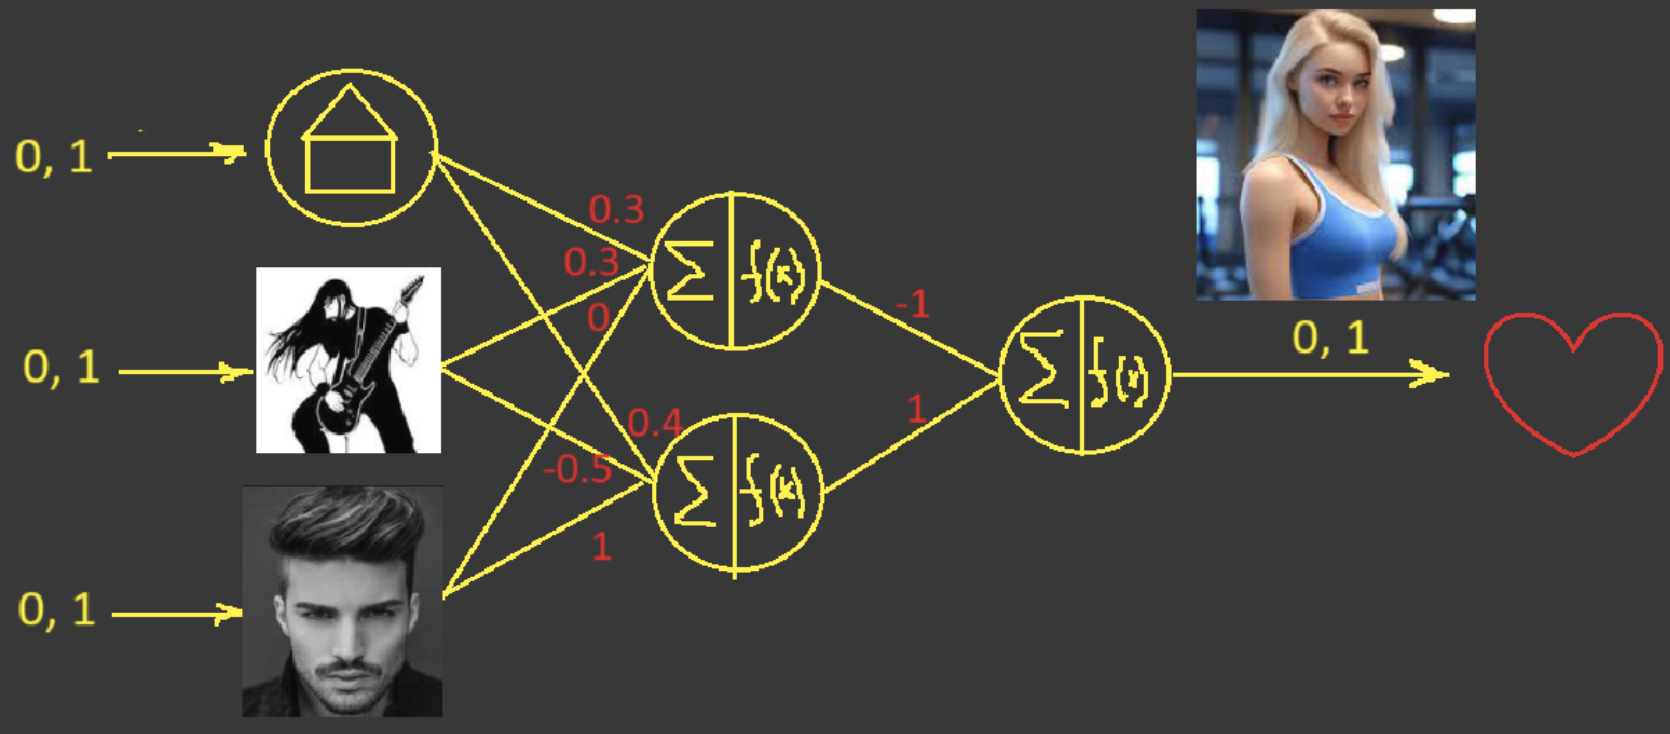

In [ ]:
#@title Как читать схему: сумма, порог, следующий слой { display-mode: "form" }
display(HTML(lesson10_viz('<div class="box def"><div class="t">Нейрон и вес</div><p><b>Искусственный нейрон</b> в этой задаче — вычислительный узел, который сначала складывает входящие сигналы с заданными весами, затем применяет к сумме функцию активации. <b>Вес</b> — числовой коэффициент на стрелке: он умножается на сигнал, проходящий по этой стрелке.</p></div><p><b>Нейросеть</b> объединяет такие узлы: выходы одних нейронов становятся входами других.</p><p>Три значка слева только передают значения признаков. Два кружка посередине — <b>скрытый слой</b>: промежуточные нейроны, результаты которых поступают следующему нейрону. Кружок справа — <b>выходной нейрон</b>, который выдаёт итоговое решение.</p><div class=\'d10-equation\'>$$s=\\sum_{i=1}^{n}w_i u_i.$$</div><div class=\'where\'><b>Обозначения.</b> $s$ — взвешенная сумма внутри нейрона; $u_i$ — его $i$-й входящий сигнал; $w_i$ — вес этого сигнала; $n$ — число входов; $\\sum$ означает сумму по всем входам. У скрытого нейрона три входа, у выходного — два.</div><div class="box def"><div class="t">Пороговая функция активации</div><p><b>Функция активации</b> преобразует взвешенную сумму в выходной сигнал нейрона. Здесь у всех трёх нейронов одна и та же пороговая функция:</p><div class=\'d10-equation\'>$$f(s)=\\begin{cases}1,&s\\ge0.5,\\\\0,&s<0.5.\\end{cases}$$</div><div class=\'where\'><b>Обозначения.</b> $s$ — взвешенная сумма; $f(s)$ — выход нейрона, 0 или 1; $0.5$ — порог.</div></div><div class="box warn"><div class="t">На границе</div>Если сумма равна ровно <b>0,5</b>, нейрон выдаёт <b>1</b>. Порог применяется после взвешенной суммы в каждом нейроне. На выходной нейрон поступают уже нули и единицы скрытого слоя.</div><p>Веса на схеме уже заданы, дополнительных слагаемых нет. Нужно только выполнить расчёт слева направо; обучение нейросети в эту задачу не входит.</p>')))

In [ ]:
#@title Что нужно реализовать { display-mode: "form" }
display(HTML(lesson10_viz('<ol><li>Напишите <code>activation(s)</code>: функция должна применять заданный порог и к одному числу, и к каждому элементу массива.</li><li>По картинке заполните матрицу <code>W_hidden</code> размера <b>2 × 3</b>. Первая строка — веса верхнего скрытого нейрона, вторая — нижнего. Столбцы: недвижимость, рок, внешность.</li><li>В функции <code>choose_partner(x)</code> одним матричным умножением получите две суммы скрытого слоя. Примените к ним порог.</li><li>Посчитайте взвешенную сумму выходного нейрона по двум полученным сигналам и весам −1 и 1. Ещё раз примените порог и верните итоговые 0 или 1.</li><li>Проверьте все восемь комбинаций признаков с помощью подготовленной таблицы.</li></ol><div class="box idea"><div class="t">Подсказка по NumPy</div>Сравнение массива с числом выполняется поэлементно и даёт <code>True</code> или <code>False</code>. Метод <code>.astype(int)</code> переводит эти значения в 1 или 0. <code>np.asarray(s)</code> позволяет одинаково начать обработку числа и массива.</div>')))

**Объясните результат**

1. Для входа `x = [0, 1, 1]` посчитайте вручную обе суммы скрытого слоя, его выходы и решение выходного нейрона.
   Где в этом расчёте важно условие «больше **или равно** 0,5»?
2. Что делает отрицательный вес −1 перед выходным нейроном?
3. Почему выходному нейрону нужно передавать результаты активации, а не исходные суммы скрытого слоя?

_Ваш ответ: …_

**Источники и повторение**

- [Занятие 1: векторы и линейные комбинации](01_vectors.ipynb).
- [Занятие 2: скалярное произведение](02_dot_product.ipynb).
- [3Blue1Brown: геометрический смысл матриц](https://www.3blue1brown.com/lessons/linear-transformations/).
- [3Blue1Brown: умножение как последовательность преобразований](https://www.3blue1brown.com/lessons/matrix-multiplication/).
- [NumPy: поведение `np.dot` для разных форм массивов](https://numpy.org/doc/stable/reference/generated/numpy.dot.html).
- [NumPy: `np.matmul` и оператор `@`](https://numpy.org/doc/stable/reference/generated/numpy.matmul.html).
- [Davis: источник шести наблюдений, закреплённая версия](https://huggingface.co/datasets/aiacademy-kg/davis_dataset/tree/cfb0d88e0d0a8814998ecfb36179bd18d0cbbb5a).